In [1]:
import os
import ast
import glob
import math
import pickle
import numpy as np
import pandas as pd
import configparser
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

config = configparser.ConfigParser()
config.read('configurations.config')
versions = ast.literal_eval(config['general']['versions'])
number_of_versions = len(versions)
work_dir = config['general']['work_dir']
# define the regional-scale sites information
sites_geo_info_file = config['Regional_Simulation']['Sites_Geo_Info']
sel_fields = gpd.read_file(sites_geo_info_file)
number_of_sites = len(sel_fields)
flux_tower_list = ast.literal_eval(config['Flux_Tower_Simulation']['flux_tower_list'])
number_of_flux_towers = len(flux_tower_list)
# Get the information that for the canola sites
canola_sites_list = ast.literal_eval(config['Canola_Simulation']['canola_sites_list'])
number_of_canola_sites = len(canola_sites_list)
cover_crop_sites = ast.literal_eval(config['Cover_Crop_Simulation']['cover_crop_sites'])
cover_crop_scenarios = ast.literal_eval(config['Cover_Crop_Simulation']['cover_crop_scenarios'])
number_of_cover_crops = len(cover_crop_sites) * len(cover_crop_scenarios)
# get the IPLOWs (mixing coefficients) (tillage intensity)
IPLOWs = ast.literal_eval(config['general']['IPLOWs'])
DPLOWs = ast.literal_eval(config['general']['DPLOWs'])
number_of_IPLOWs = len(IPLOWs)
number_of_DPLOWs = len(DPLOWs)
figure_dir = os.path.join(work_dir, 'generated_figures')
file_of_npgs = glob.glob(f'{figure_dir}/**/*.png', recursive = True)
print(f'There are {len(file_of_npgs)} figures generated.')

failure_cases = ['20_sites', 'flux_towers', 'cover_crops', 'N_responses']
case_total_counts = {
    '20_sites': 4480,    # 20 sites * 4 tillage intensities * 4 mixing coefficients * (2021 - 2008 + 1) years
    'flux_towers': 71,  
    'cover_crops': 6180, # 6 site * 10 scenarios * (2114 - 2012 + 1) years
    'N_responses': 462   # 7 sites * 3 years * 22 fertilization scenarios    
}
total_counts = 11193     # 4480 + 71 + 6180 + 462
def show_plots(ncols, nrows, folder, effects, file_names, figsize=(12, 8), subtitle=None):
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    # Flatten axs for easier indexing regardless of shape
    axs = axs.flatten()
    if subtitle:
        fig.suptitle(subtitle, fontsize=18)
    for i, effect in enumerate(effects):
        img_path = os.path.join(folder, file_names[i])
        if os.path.exists(img_path):
            img = mpimg.imread(img_path)
            axs[i].imshow(img)
            axs[i].axis('off')
        else:
            print(f"Warning: {img_path} not found.")
            axs[i].axis('off')
    # Turn off unused axes
    for j in range(len(effects), len(axs)):
        fig.delaxes(axs[j])
    plt.tight_layout()
    plt.show()
    plt.clf()
    plt.close()

There are 29080 figures generated.


In [2]:
from IPython.display import display, HTML

# Load all failure data once
# tuple structure per version:
#   (failed_counts/total_counts,
#    crushed_SOC, crushed_Yield, crushed_N2O,
#    irrational_SOC, irrational_Yield, irrational_N2O)
failure_data = {}
for case in failure_cases:
    cur_failure_file = os.path.join(work_dir, f'failure_results_on_{case}.pkl')
    with open(cur_failure_file, 'rb') as f:
        failure_data[case] = pickle.load(f)

# Table 1: Failure Ratios per Version
ratio_rows = []
for version in versions:
    row = {'Versions': version}
    total_failed = 0
    for case in failure_cases:
        cnt = int(failure_data[case][version][0] * case_total_counts[case])
        row[case] = cnt
        total_failed += cnt
    row['failed_counts'] = total_failed
    row['average_ratio'] = f"{total_failed / total_counts * 100:.2f}%"
    ratio_rows.append(row)

ratio_df = pd.DataFrame(ratio_rows).rename(columns={
    '20_sites': '20 Sites',
    'flux_towers': 'Flux Towers',
    'cover_crops': 'Cover Crops',
    'N_responses': 'N Responses',
    'failed_counts': 'Failed Counts',
    'average_ratio': 'Average Ratio',
})

# Table 2: Failure Details per Version
# indices 1-3 → crushed_*; indices 4-6 → irrational_*
failure_type_labels = [
    'crushed_SOC',    'crushed_Yield',    'crushed_N2O',
    'irrational_SOC', 'irrational_Yield', 'irrational_N2O',
]
case_col_map = list(zip(failure_cases, ['20 Sites', 'Flux Towers', 'Cover Crops', 'N Responses']))

detail_rows = []
for version in versions:
    for ft_idx, ft_label in enumerate(failure_type_labels, start=1):
        row = {
            'Versions': version if ft_idx == 1 else '',
            'Failure Type': ft_label,
        }
        total = 0
        for case, col_name in case_col_map:
            val = failure_data[case][version][ft_idx]
            row[col_name] = val
            total += val
        row['Failed Counts'] = total
        detail_rows.append(row)

detail_df = pd.DataFrame(
    detail_rows,
    columns=['Versions', 'Failure Type', '20 Sites', 'Flux Towers', 'Cover Crops', 'N Responses', 'Failed Counts']
)

# --- Styled HTML table generator ---
def make_table_html(title, df, orange_cols=None):
    HEADER_BG = '#4472C4'
    ROW_BG_A  = '#D9E8FF'
    ROW_BG_B  = '#FFFFFF'
    ORANGE    = '#CF4520'

    th = 'padding:6px 14px;text-align:center;white-space:nowrap;border:1px solid #aac;'
    td = 'padding:5px 14px;text-align:center;border:1px solid #ccc;'

    parts = [
        f'<b style="font-size:15px;">{title}</b>',
        '<table style="border-collapse:collapse;font-size:13px;margin-bottom:24px;">',
        f'<tr style="background:{HEADER_BG};color:white;font-weight:bold;">',
    ]
    for col in df.columns:
        parts.append(f'<th style="{th}">{col}</th>')
    parts.append('</tr>')

    for i, (_, row) in enumerate(df.iterrows()):
        bg = ROW_BG_A if i % 2 == 0 else ROW_BG_B
        parts.append(f'<tr style="background:{bg};">')
        for col, val in row.items():
            color = f'color:{ORANGE};' if (orange_cols and col in orange_cols) else ''
            parts.append(f'<td style="{td}{color}">{val}</td>')
        parts.append('</tr>')
    parts.append('</table>')
    return '\n'.join(parts)

orange_cols = {'Flux Towers', 'Cover Crops', 'N Responses'}
display(HTML(make_table_html("Failure Ratios per Version",  ratio_df,  orange_cols=orange_cols)))
display(HTML(make_table_html("Failure Details per Version", detail_df, orange_cols=orange_cols)))

FileNotFoundError: [Errno 2] No such file or directory: '/work/hdd/bbkc/zhangzhy/Testing_pipeline_2/failure_results_on_20_sites.pkl'

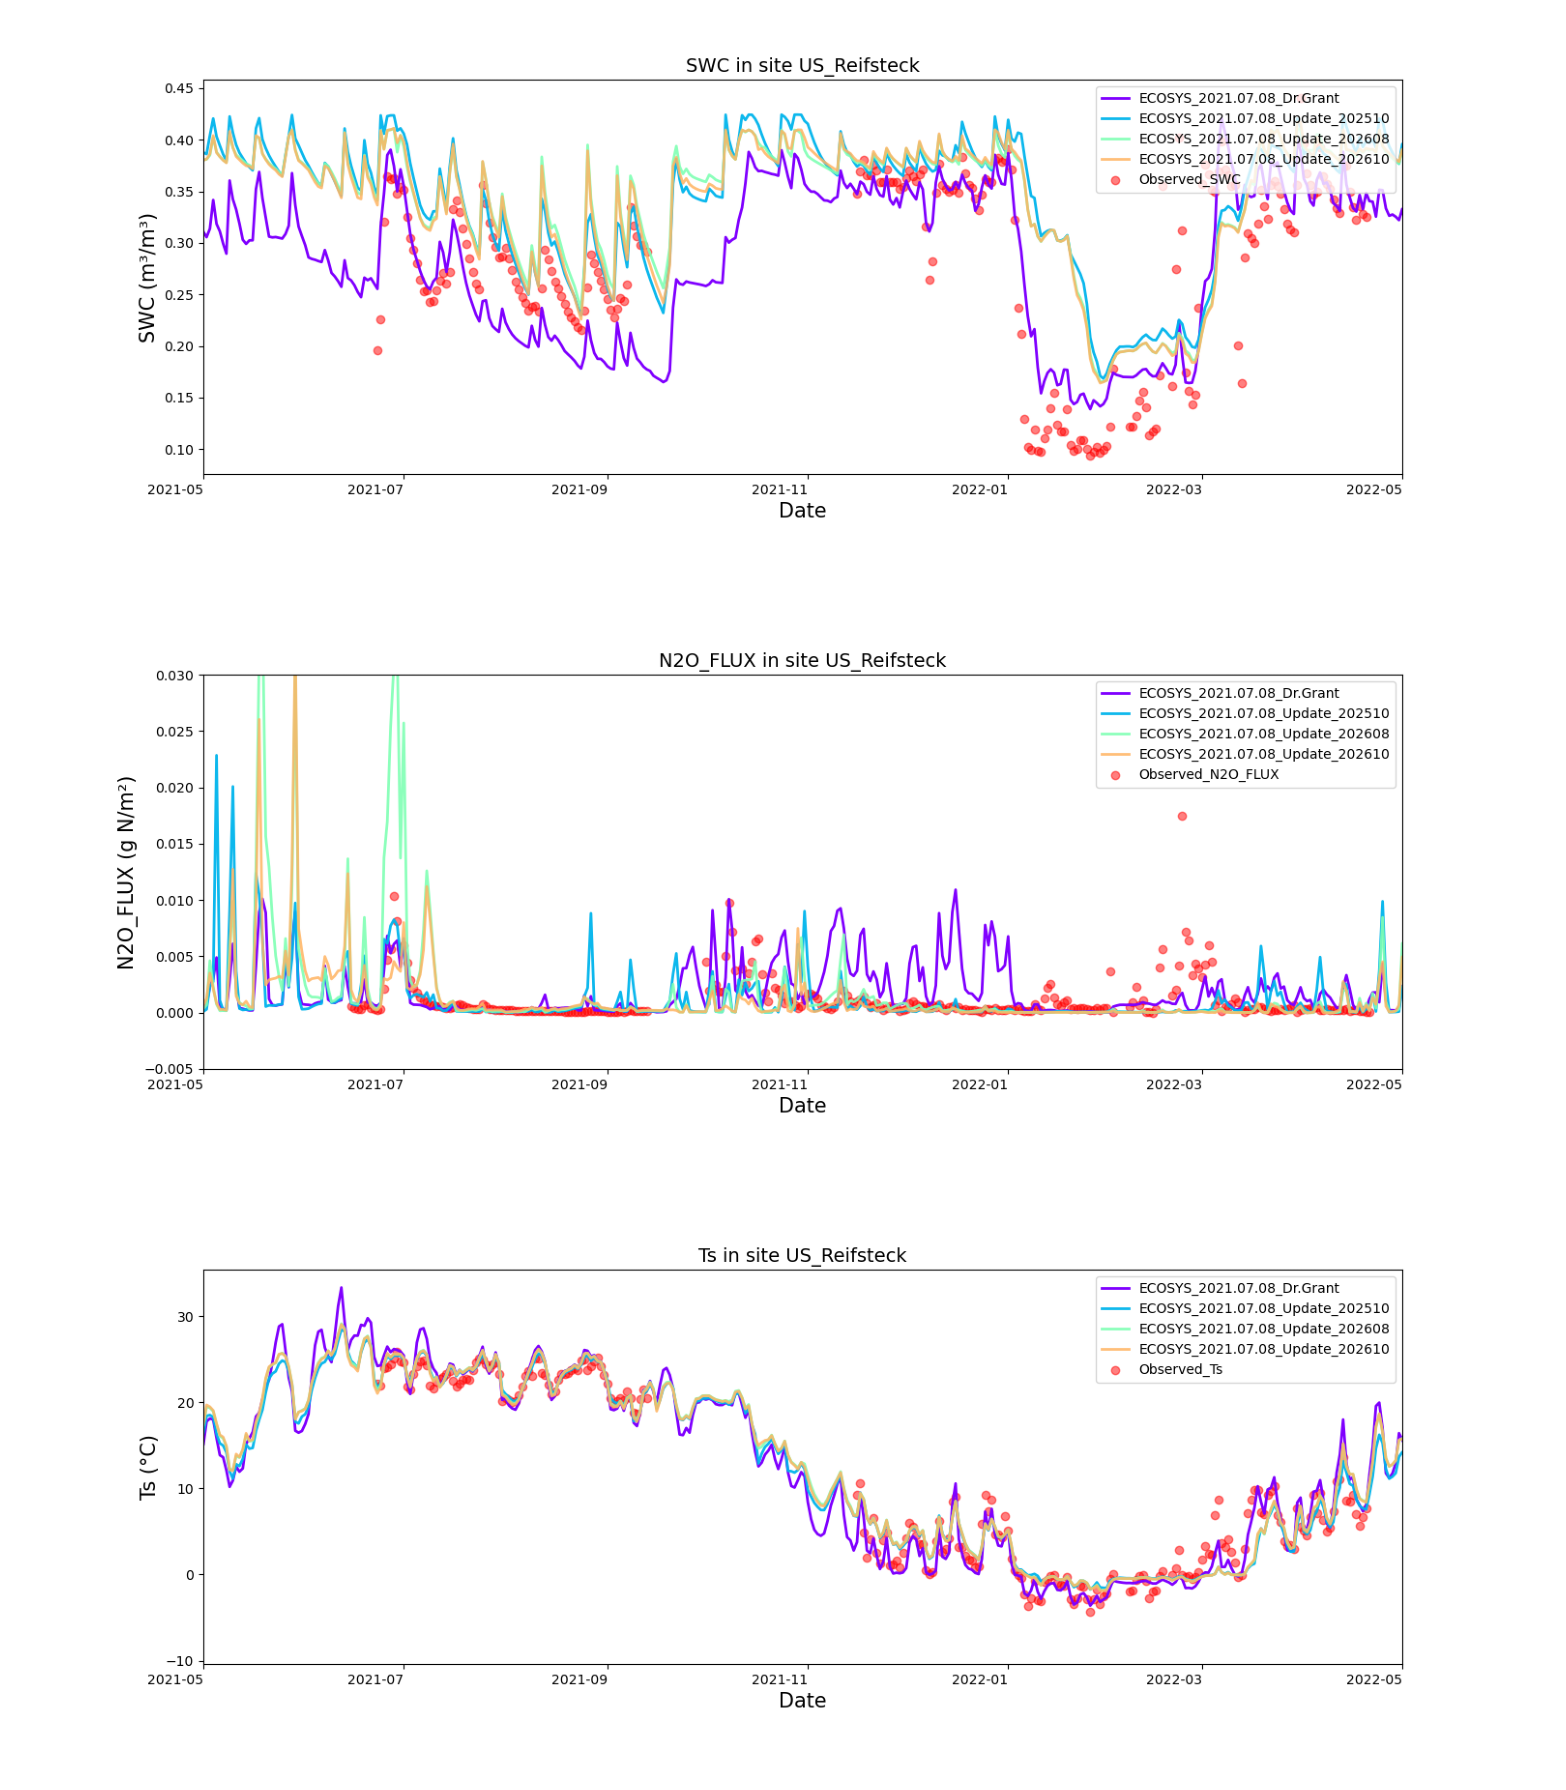

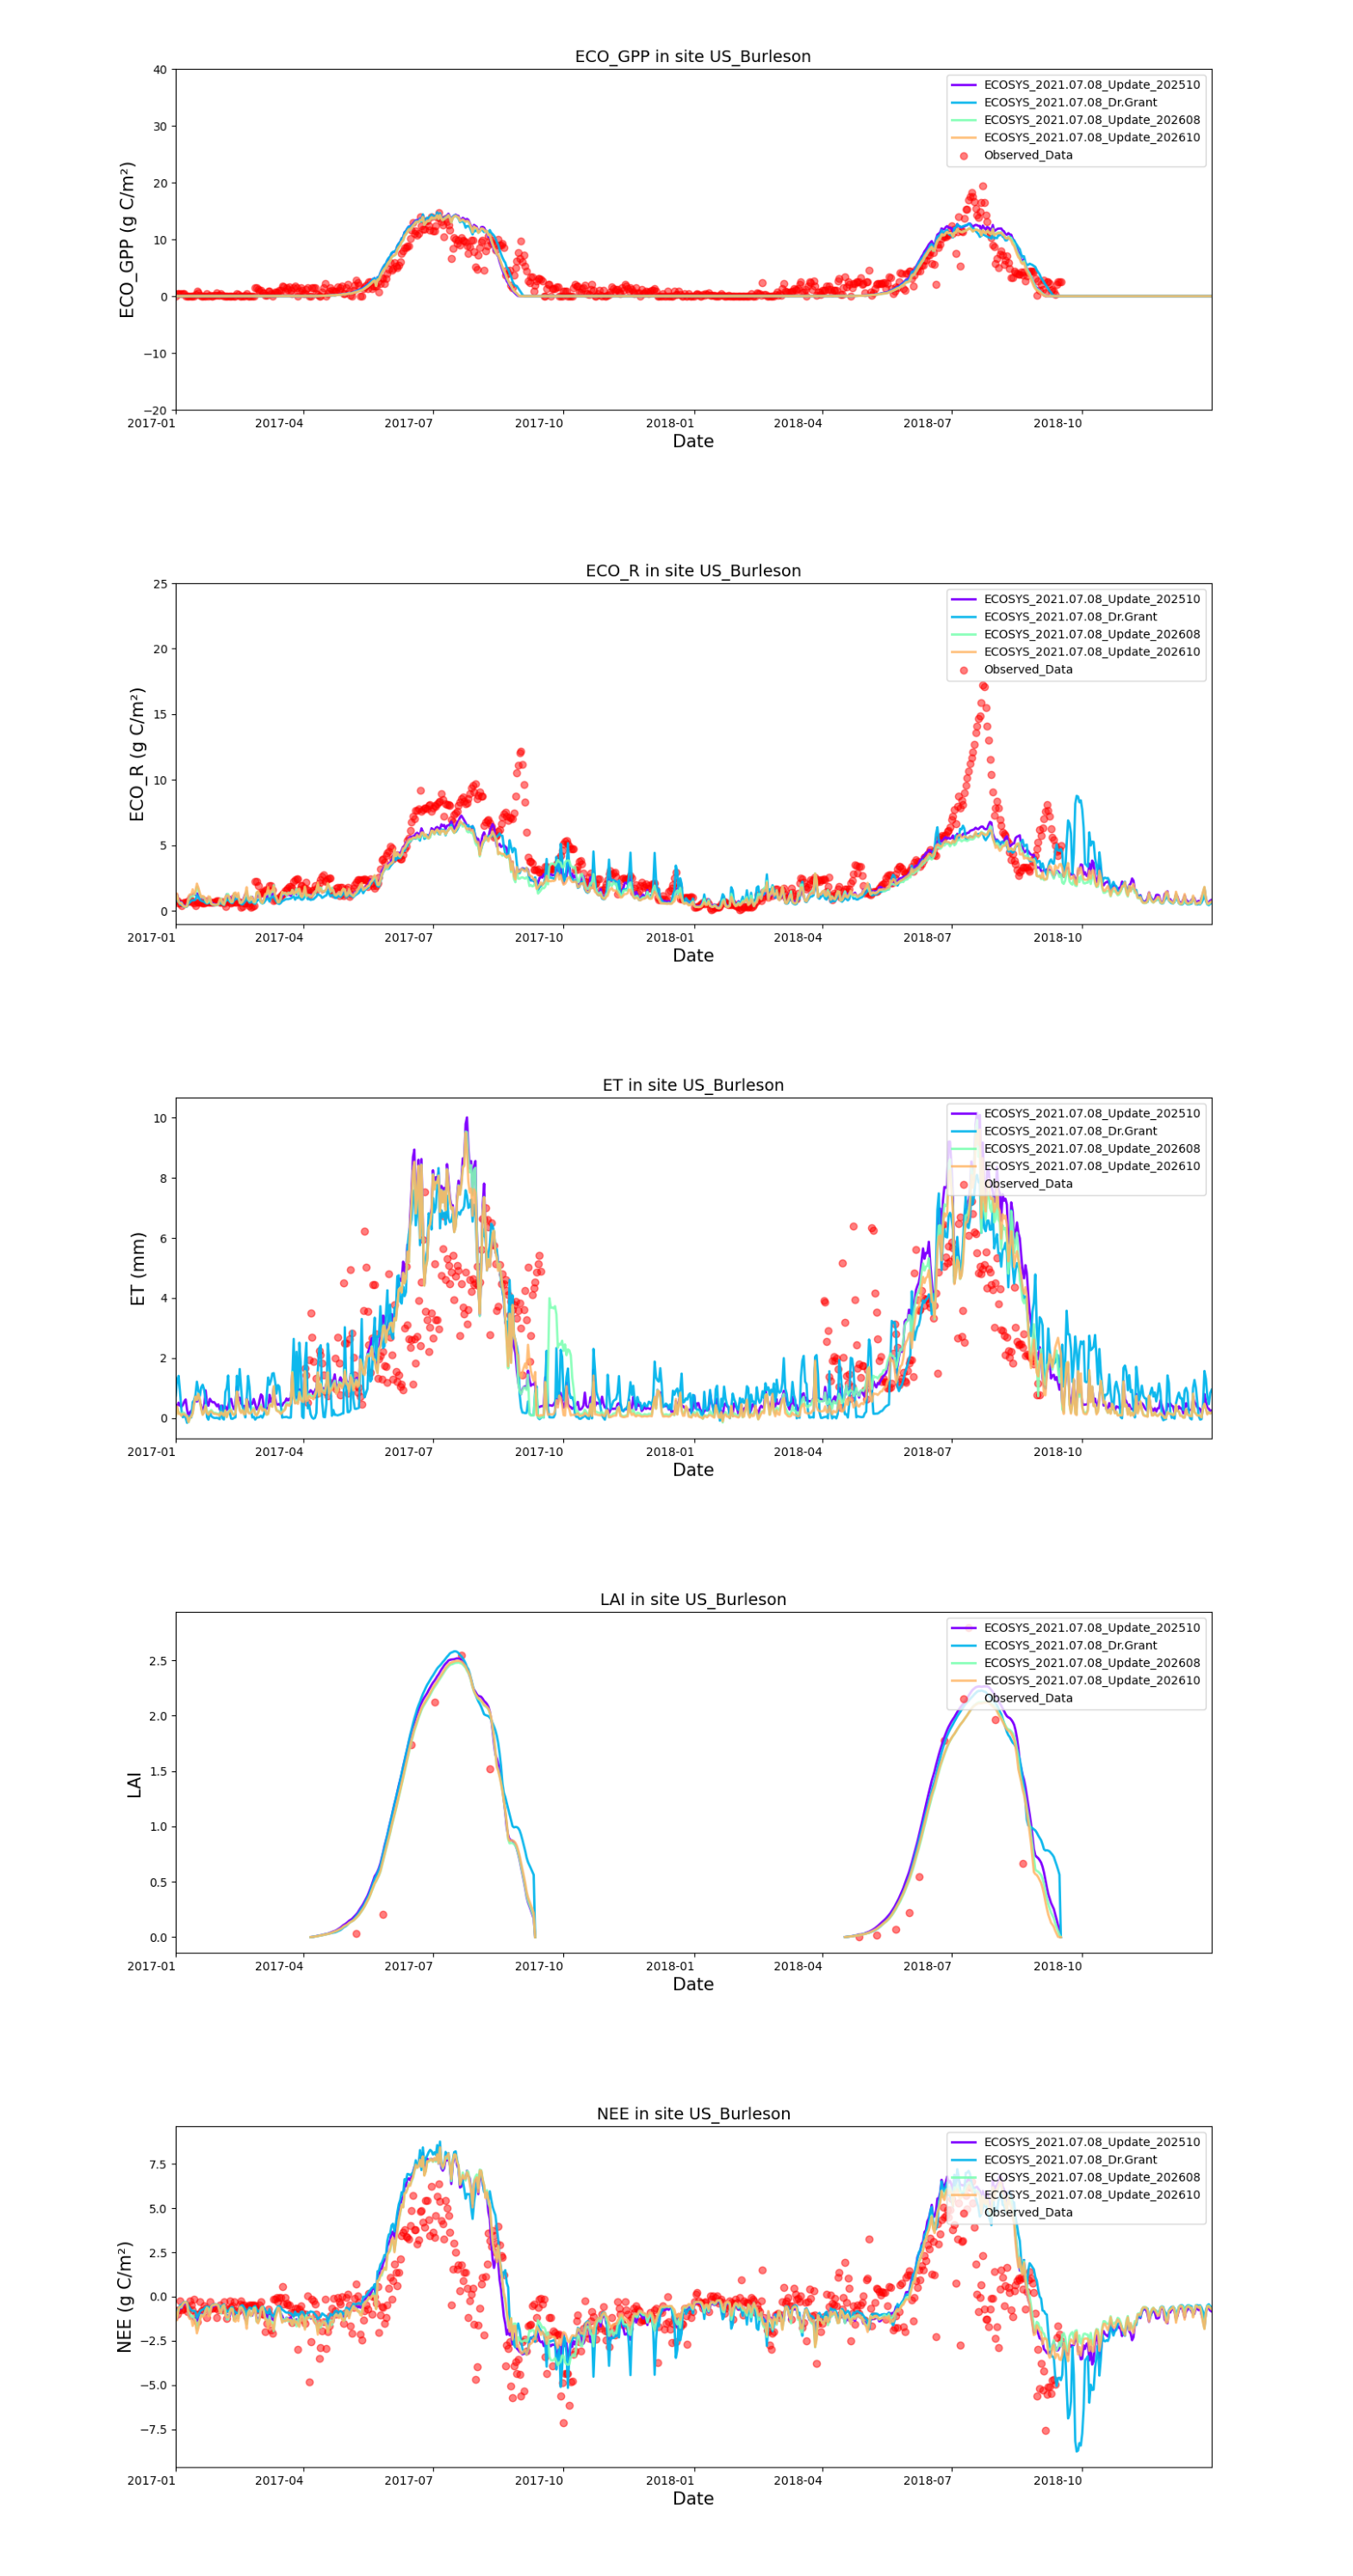

In [3]:
# Flux tower sites (US_Reifsteck and US_Burleson)
cur_folder1 = os.path.join(figure_dir, 'N2O_validation_version_effects_plots', 'US_Reifsteck')
vars = ['SWC', 'N2O_FLUX', 'Ts']
ncols = 1
nrows = int (math.ceil(len(vars) / ncols))
file_names = [f'Comparison of {var} for different versions.png' for var in vars]
show_plots(ncols, nrows, cur_folder1, vars, file_names, figsize=(ncols * 16, nrows * 6))

cur_folder2 = os.path.join(figure_dir, 'flux_towers_version_effects_plots', 'US_Burleson')
vars = ['ECO_GPP', 'ECO_R', 'ET', 'LAI', 'NEE']
ncols = 1
nrows = int (math.ceil(len(vars) / ncols))
file_names = [f'Comparison of {var} for different versions.png' for var in vars]
show_plots(ncols, nrows, cur_folder2, vars, file_names, figsize=(ncols * 16, nrows * 6))

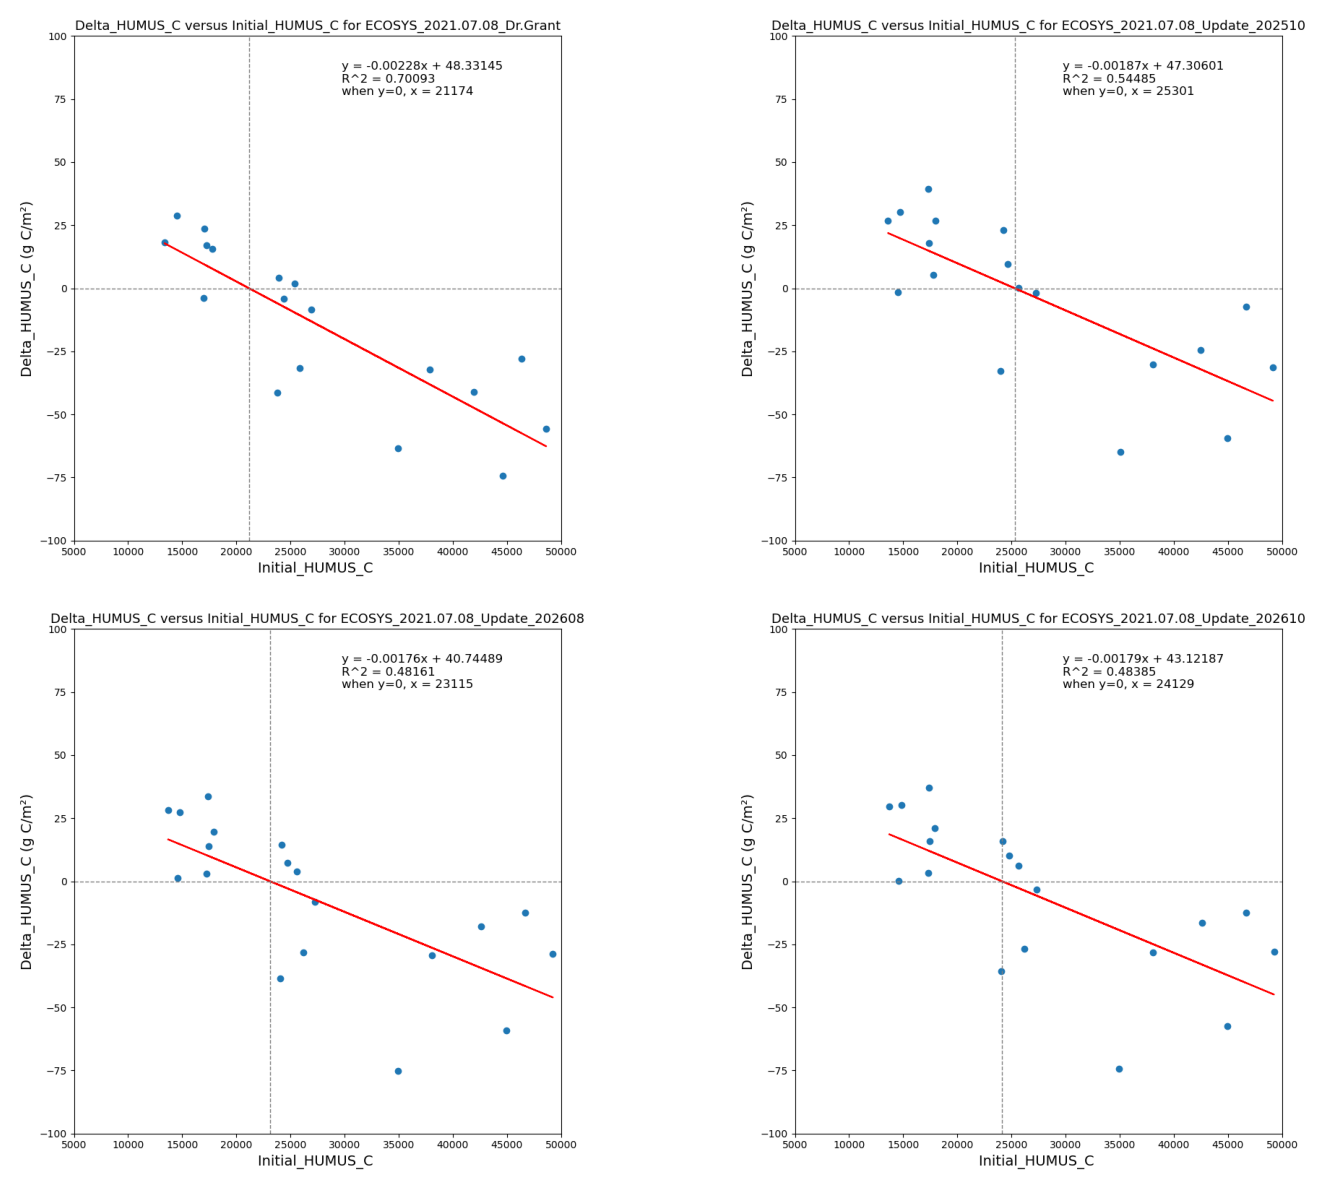

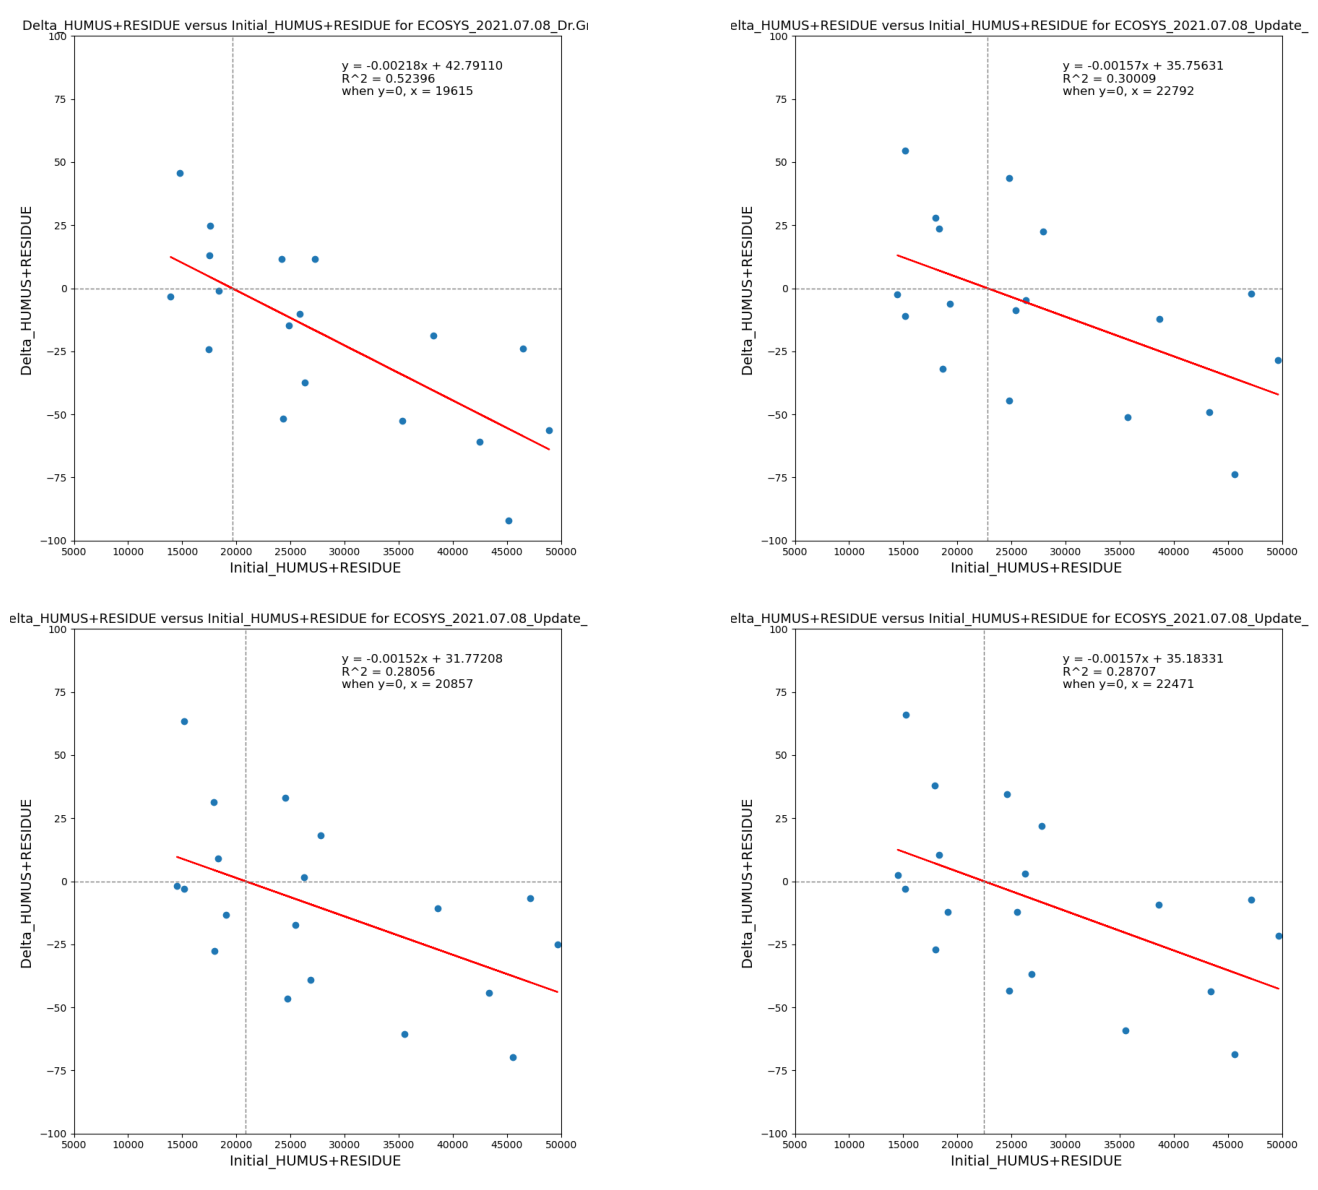

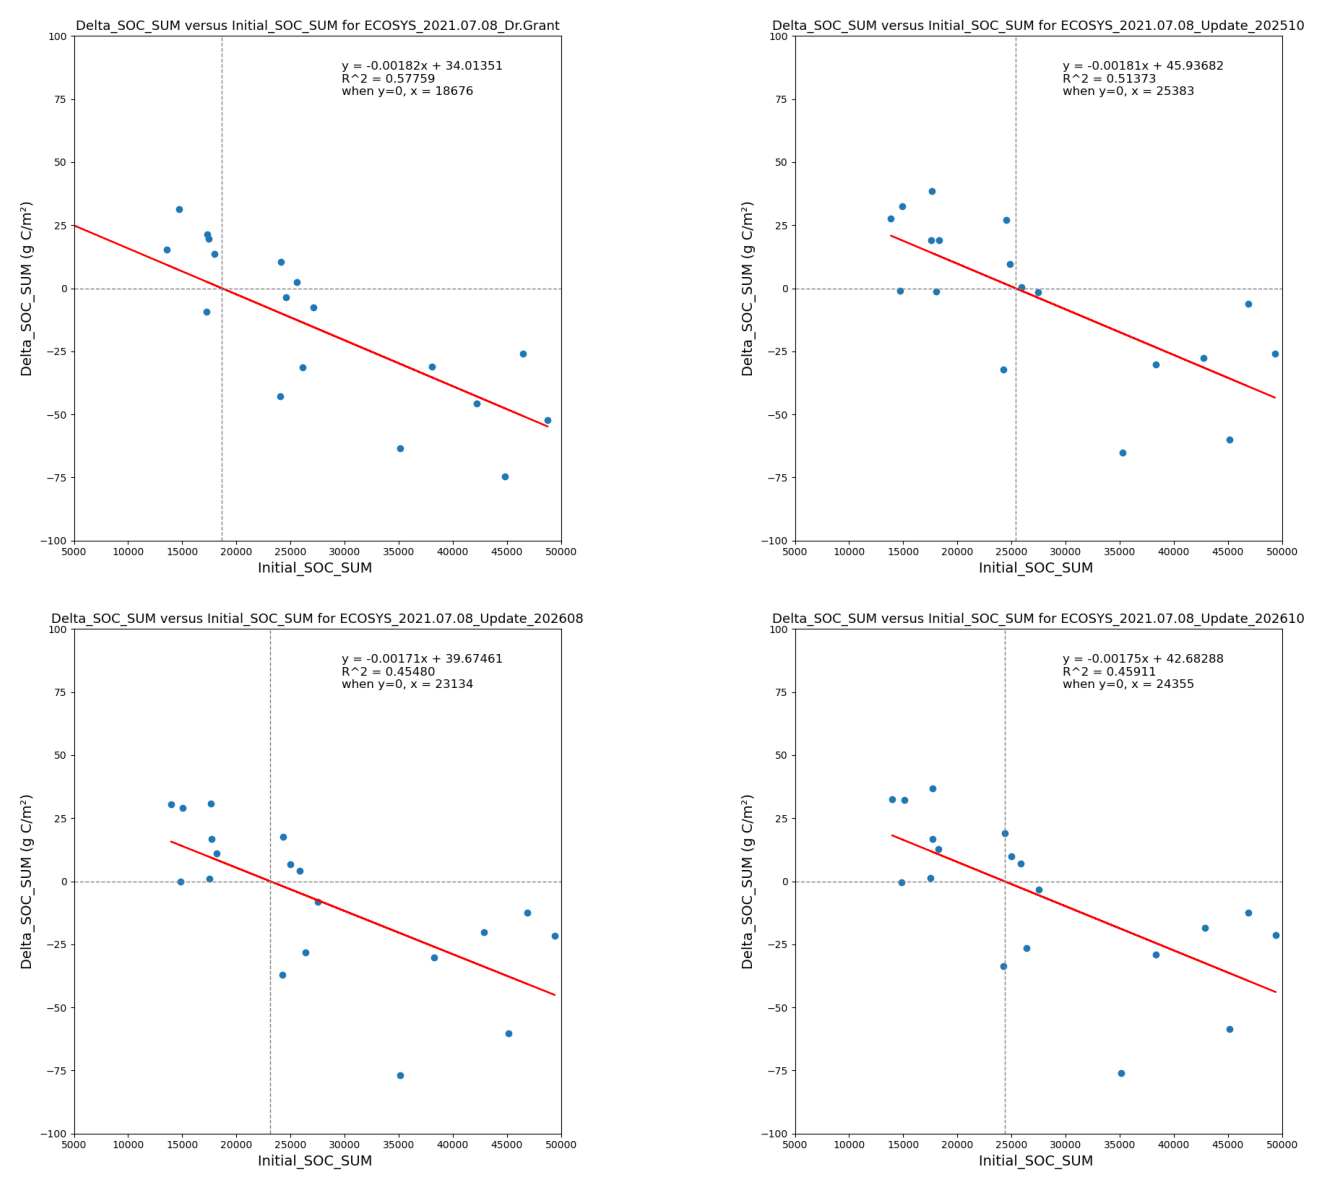

In [4]:
# show the relationship between initial SOC and delta SOC
cur_folder = os.path.join(figure_dir, 'delta_SOC_to_initial_SOC_plots')
ncols = 2
nrows = int (math.ceil(len(versions) / ncols))
file_names1 = [f'Delta_HUMUS_C versus Initial_HUMUS_C for {version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names1, figsize=(ncols * 8, nrows * 6))

file_names2 = [f'Delta_HUMUS+RESIDUE versus Initial_HUMUS+RESIDUE for {version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names2, figsize=(ncols * 8, nrows * 6))

file_names3 = [f'Delta_SOC_SUM versus Initial_SOC_SUM for {version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names3, figsize=(ncols * 8, nrows * 6))

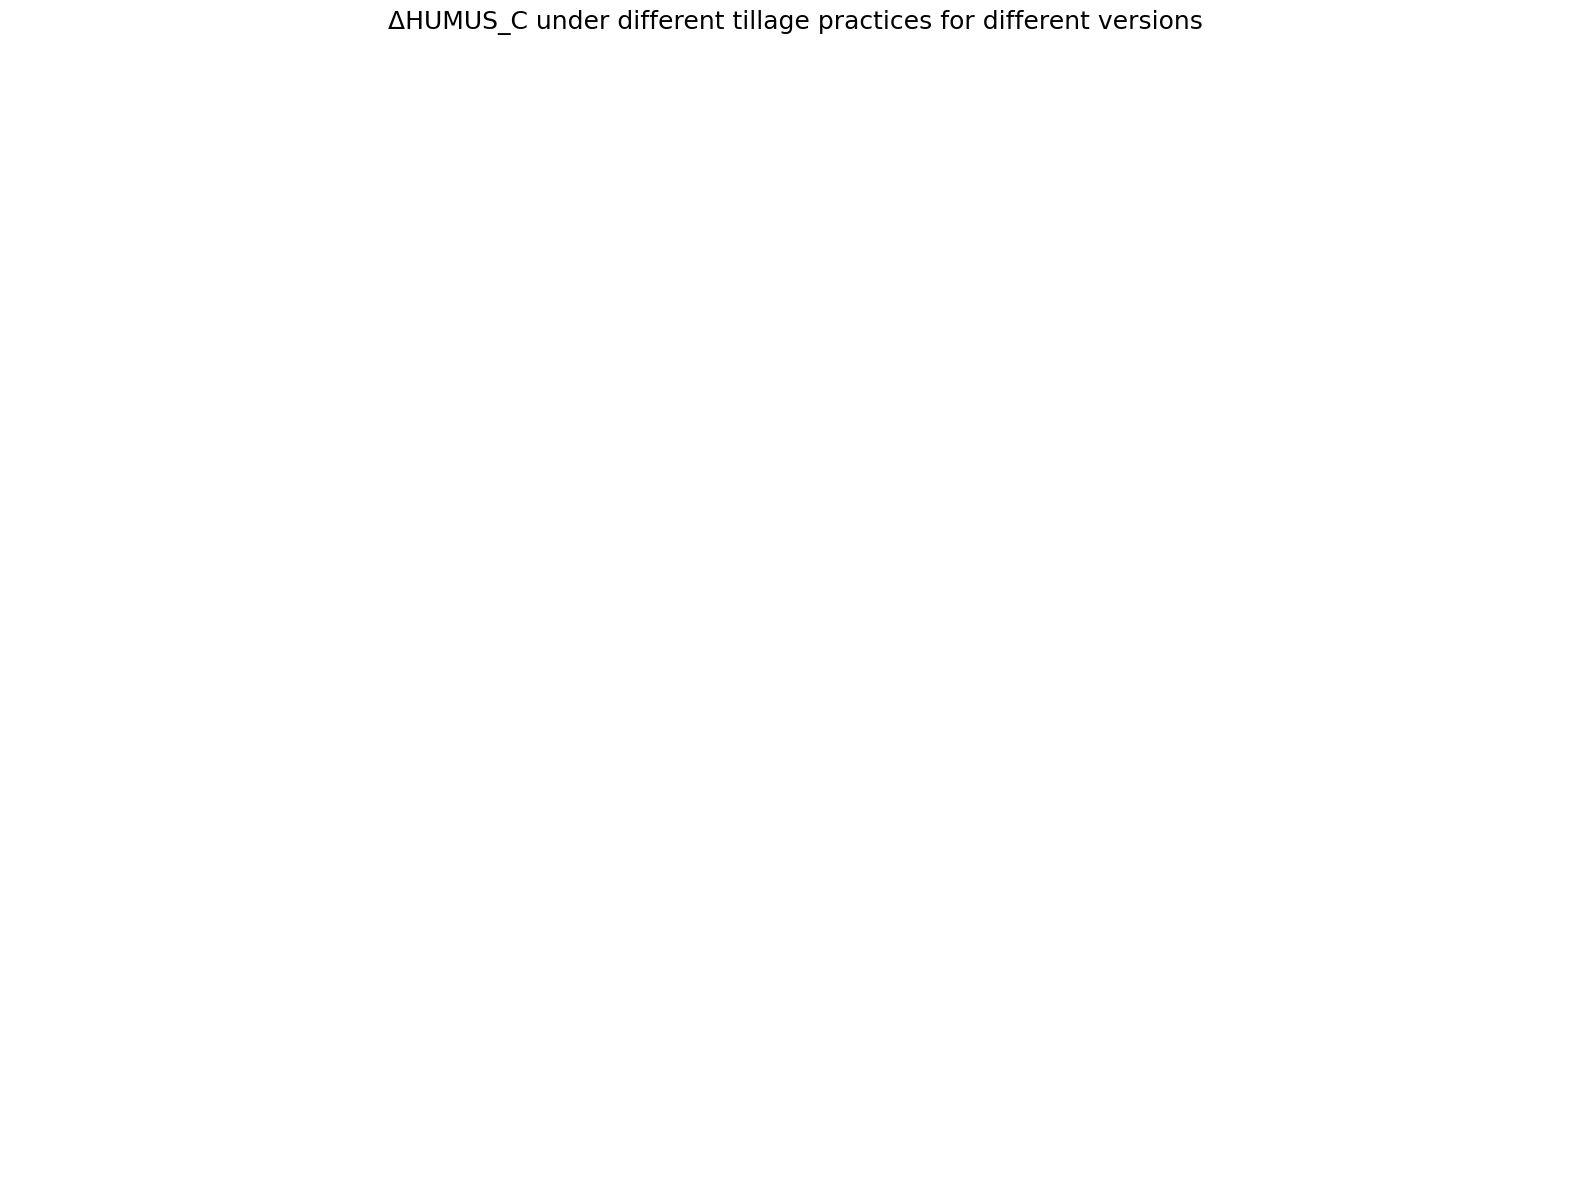

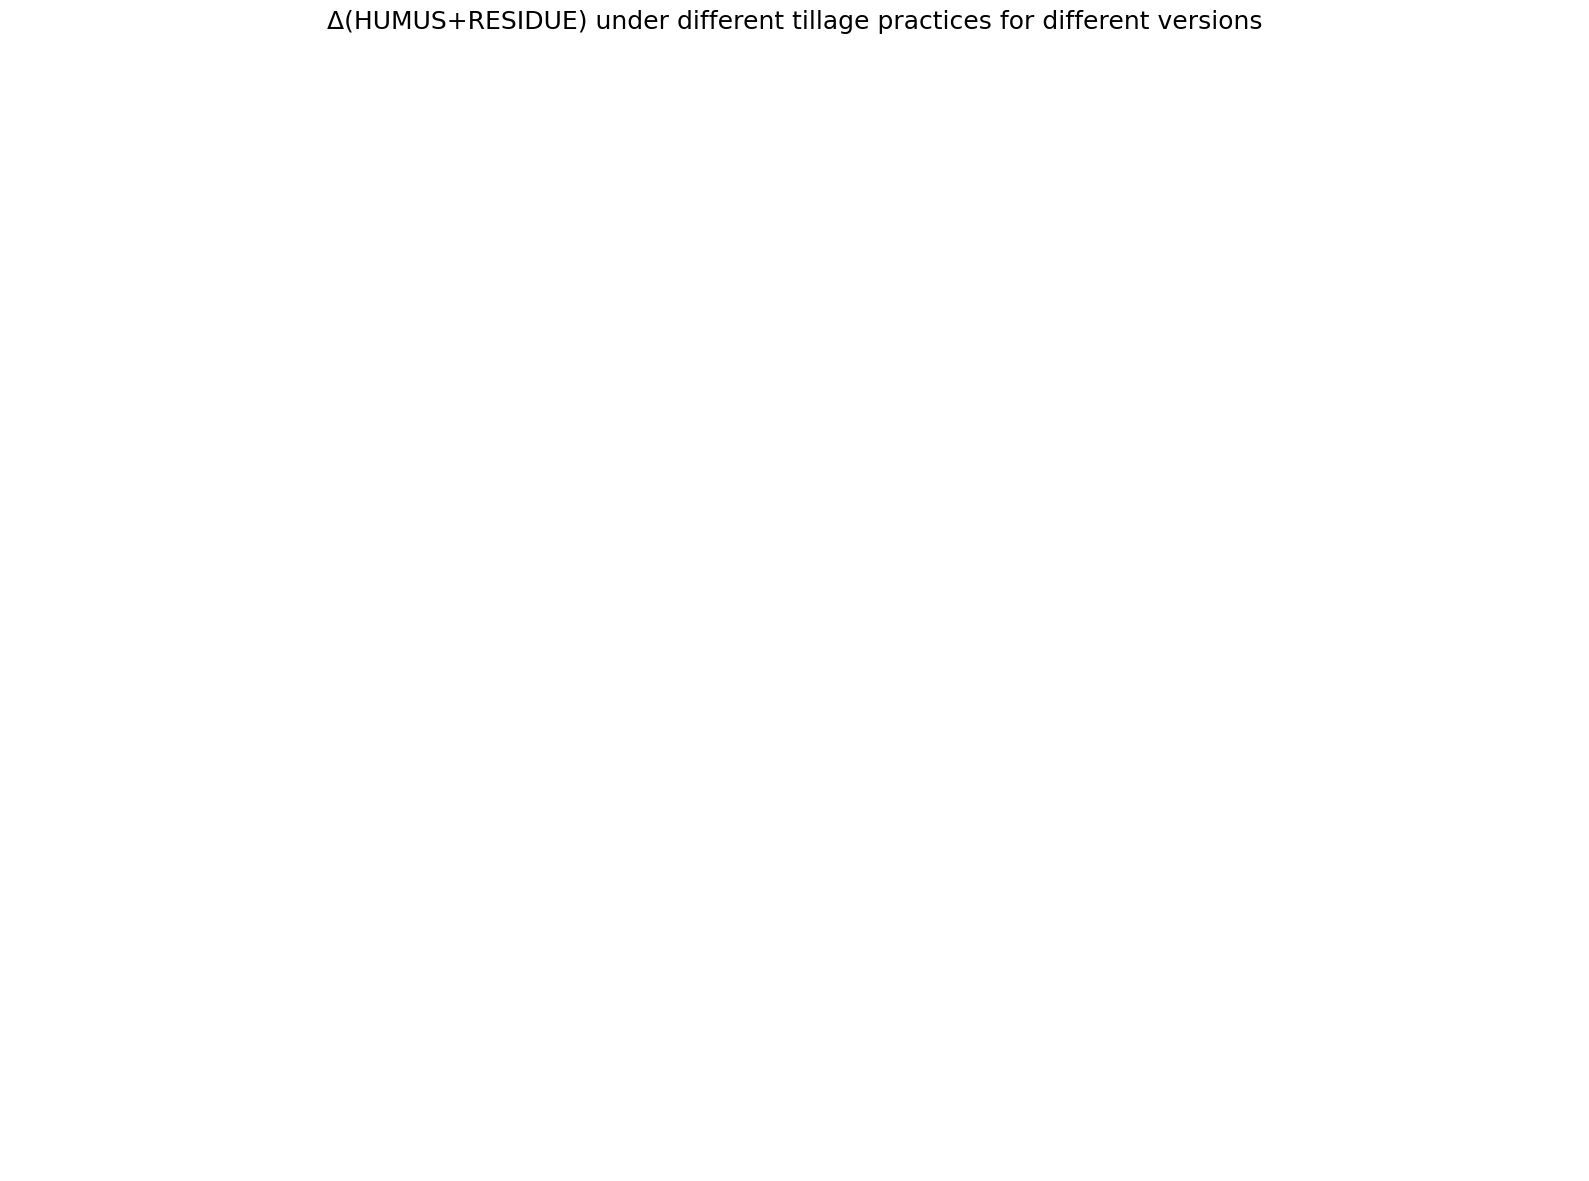

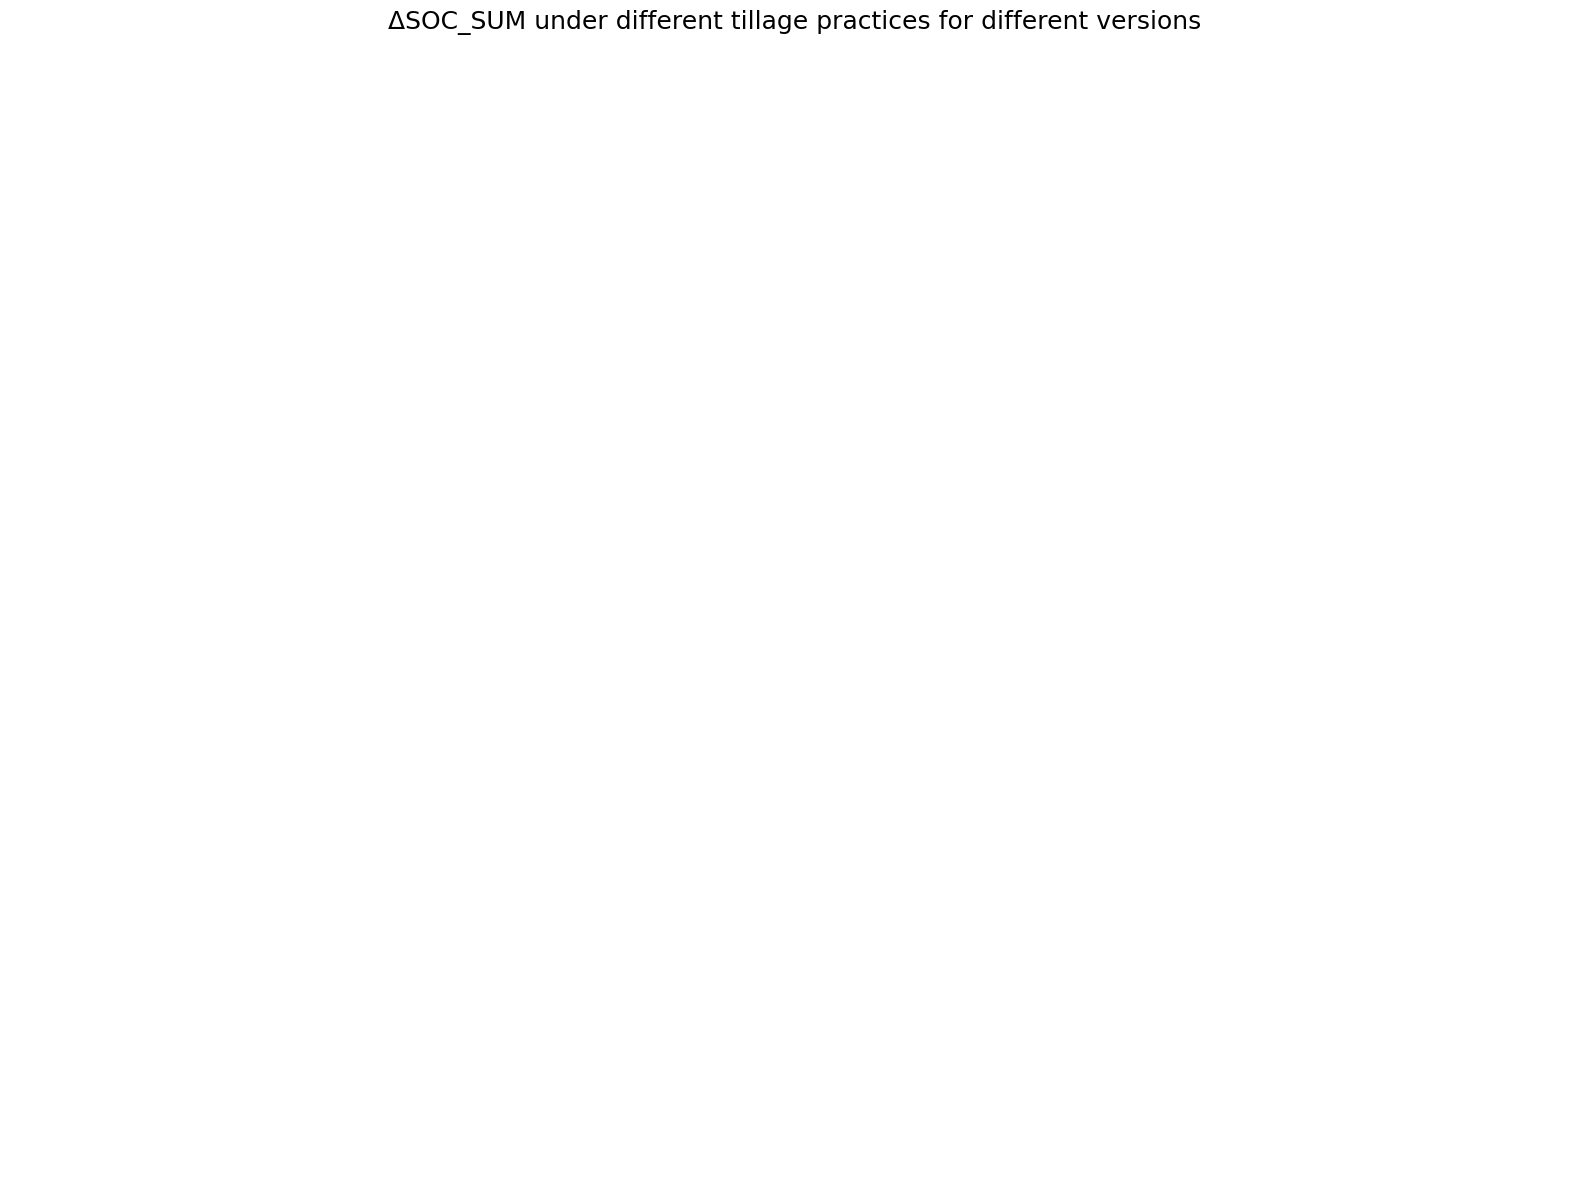

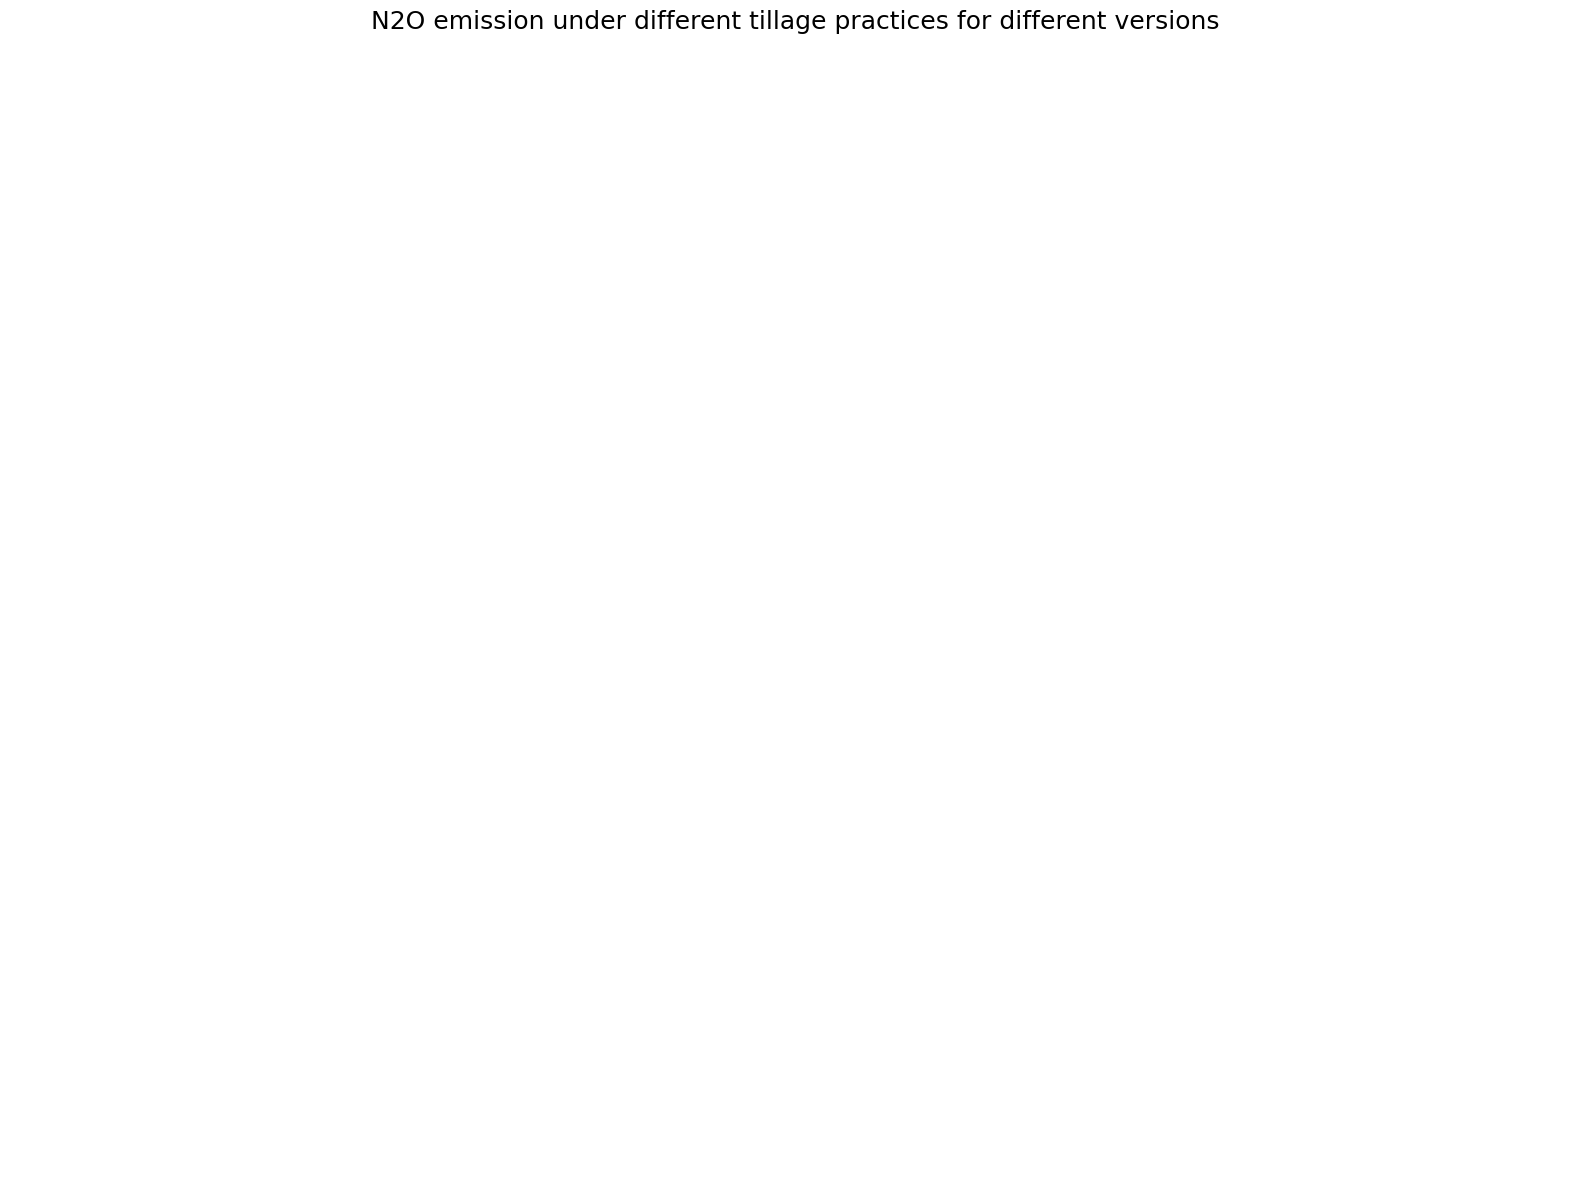

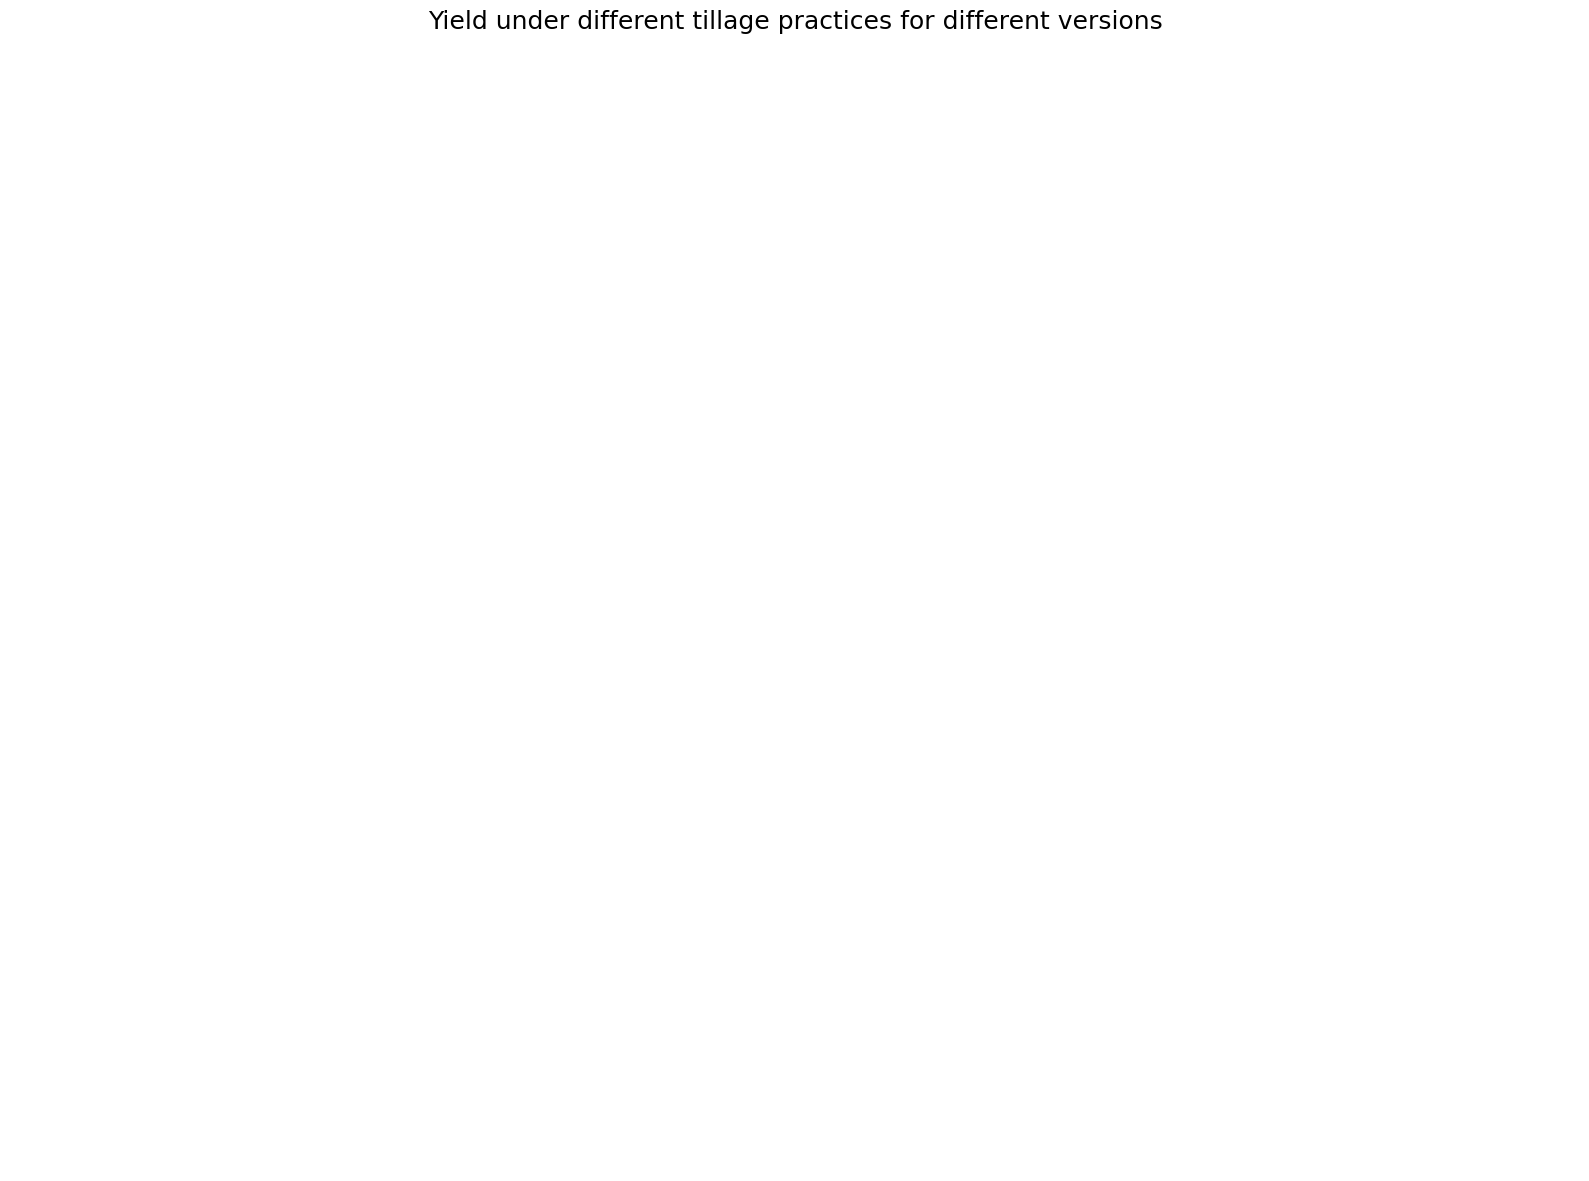

In [5]:
# SOC change and N2O emission under different tillage practices (bar plots) for different versions
cur_folder = os.path.join(figure_dir, '20_sites_tillage_effects_plots', 'Bar_plots')
vars = ['ΔHUMUS_C', 'Δ(HUMUS+RESIDUE)', 'ΔSOC_SUM', 'N2O emission', 'Yield']
for var in vars:
    ncols = 2
    nrows = int (math.ceil(len(versions) / ncols))
    file_names = [f'Bar plots of tillage effects on {var} for {version}.png' for version in versions]
    show_plots(ncols, nrows, cur_folder, versions, file_names, figsize=(ncols * 8, nrows * 6), 
               subtitle=f'{var} under different tillage practices for different versions')

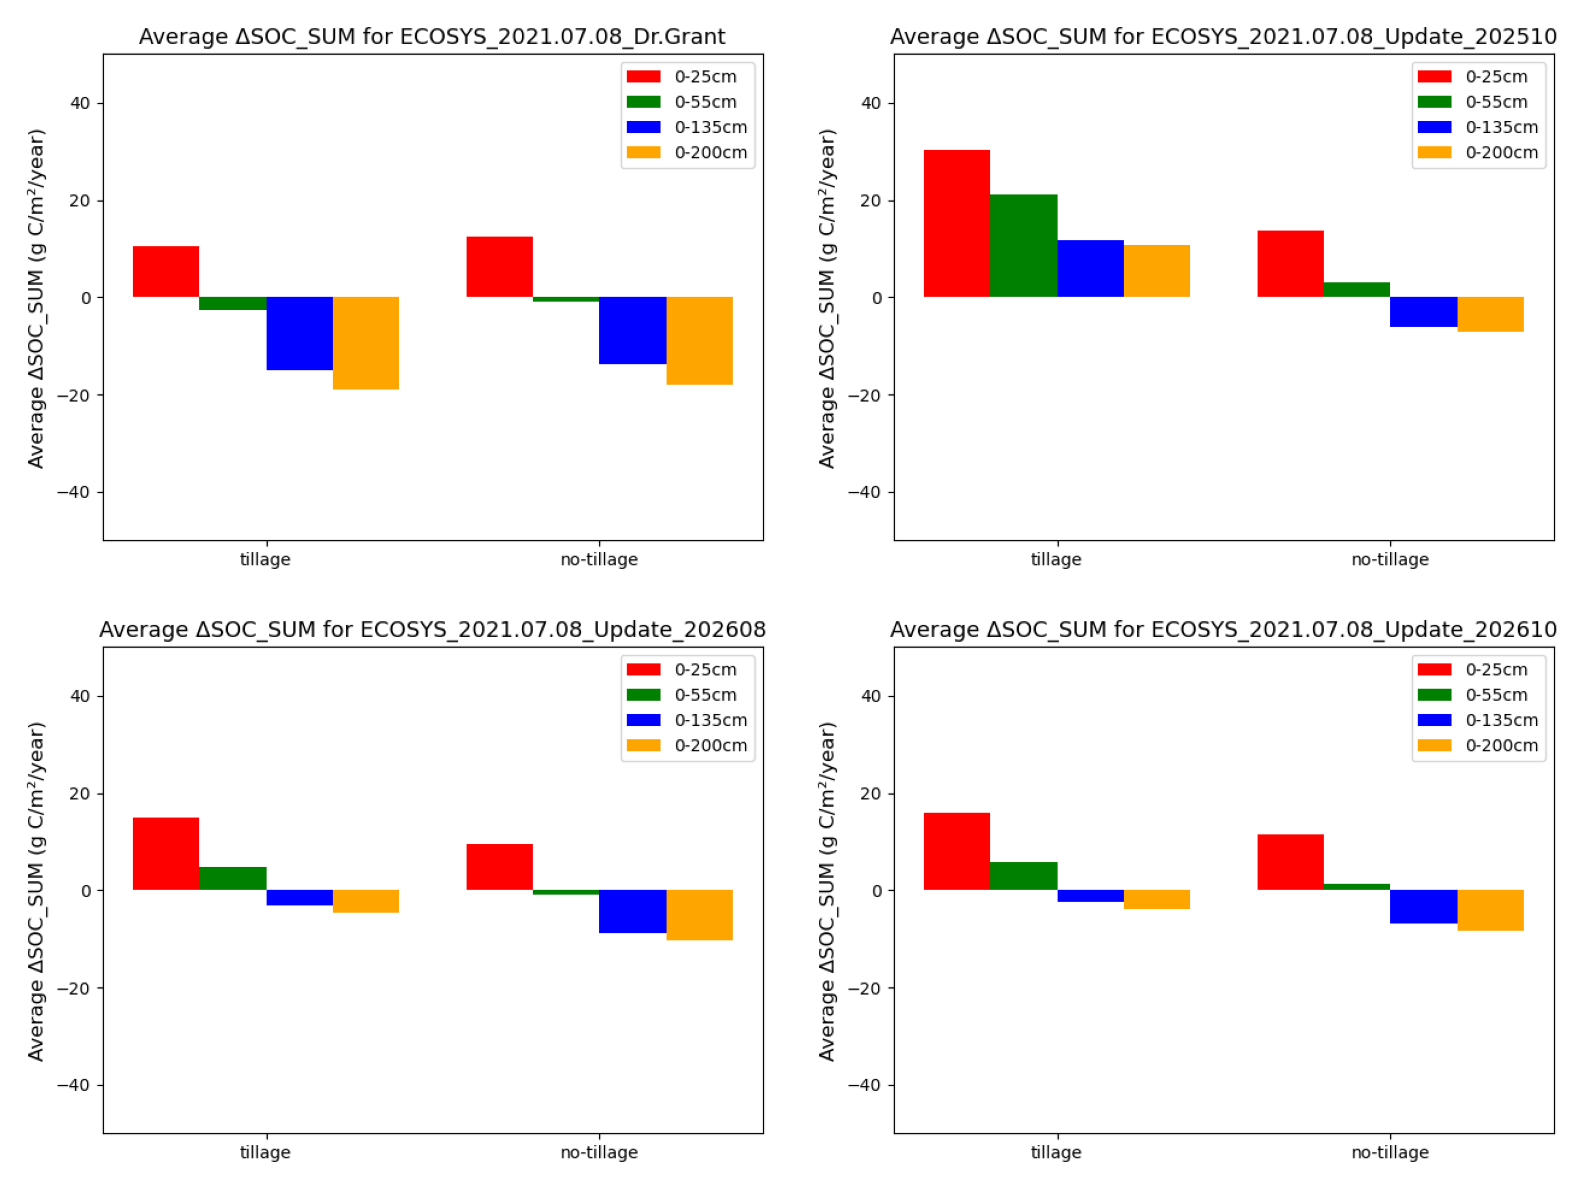

In [6]:
# SOC change at different depth (25cm, 55cm, 135cm, 200cm) for tillage and no-tillage
cur_folder = os.path.join(figure_dir, '20_sites_version_effects_plots', 'Bar_plots')
ncols = 2
nrows = int (math.ceil(len(versions) / ncols))
file_names = [f'Bar plots of depth effects on ΔSOC_SUM for {version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names, figsize=(ncols * 8, nrows * 6))

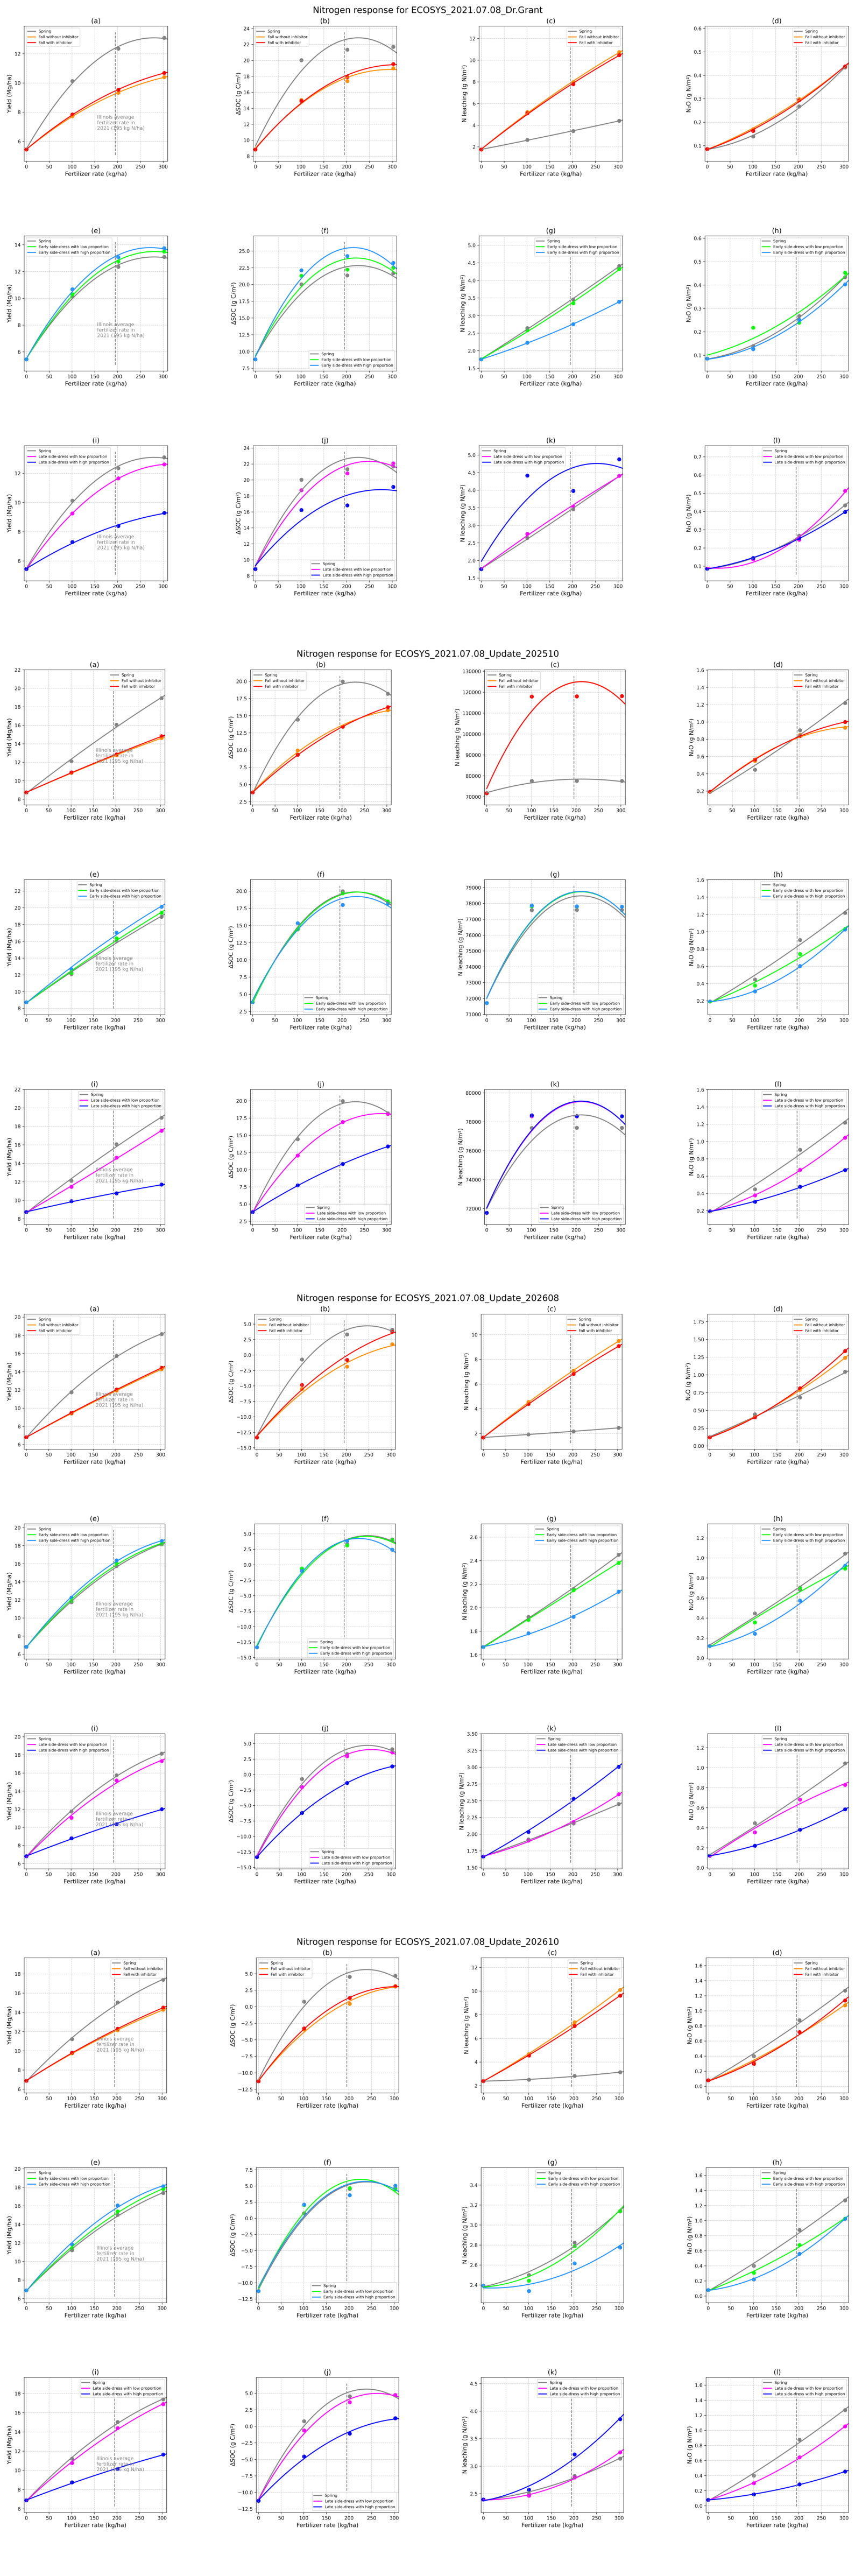

In [7]:
# Nitrogen response for differnet versions
cur_folder = os.path.join(figure_dir, 'N_response_version_effects_plots')
ncols = 1
nrows = len(versions)
file_names = [f'N_response_on_version_{version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names, figsize=(ncols * 16, nrows * 12))

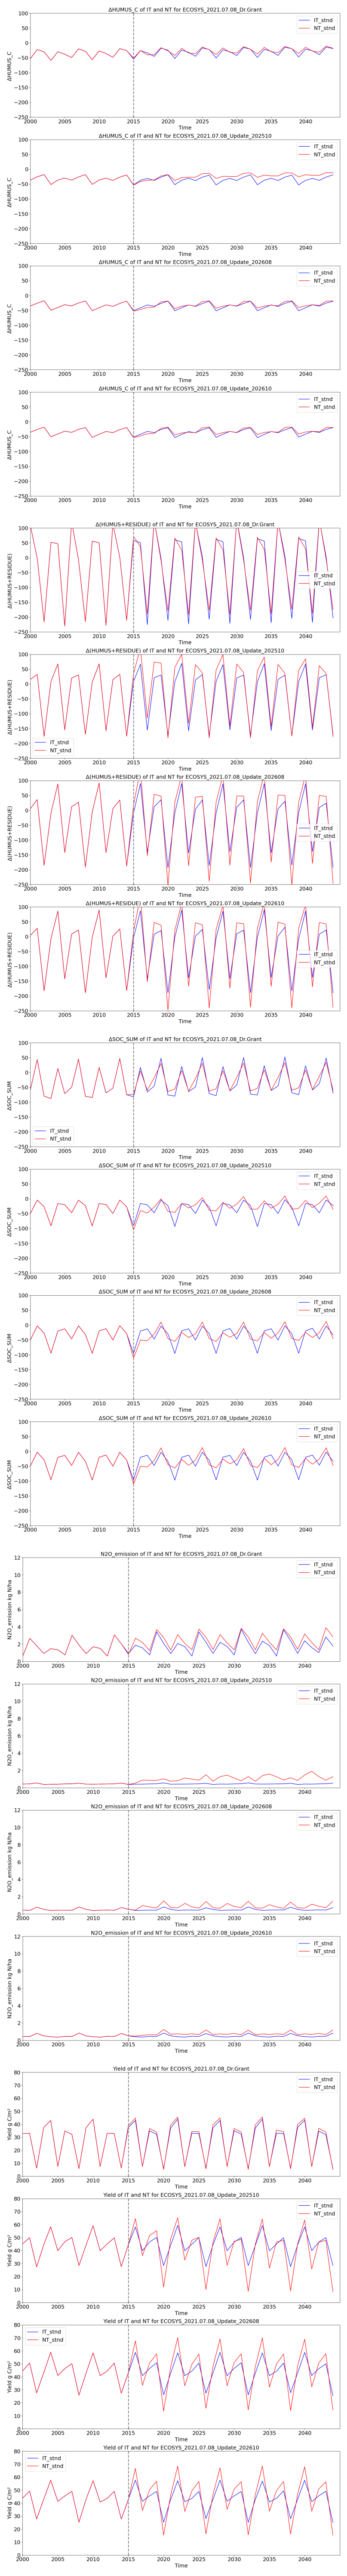

In [8]:
# Canola sites response for differnet versions
cur_folder = os.path.join(figure_dir, 'canola_sites_scenario_effects_plots', '52_10')
vars = ['ΔHUMUS_C', 'Δ(HUMUS+RESIDUE)', 'ΔSOC_SUM', 'N2O_emission', 'Yield']
ncols = 1
nrows = len(vars)
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, 12 * nrows))
axs = axs.flatten()# Flatten axs for easier indexing regardless of shape
for i, var in enumerate(vars):
    img_path = os.path.join(cur_folder, f'Comparion of {var} vs time for different scenarios for different versions.png')
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        axs[i].imshow(img)
        axs[i].axis('off')
    else:
        print(f"Warning: {img_path} not found.")
        axs[i].axis('off')
# Turn off unused axes
for j in range(len(vars), len(axs)):
    fig.delaxes(axs[j])
plt.tight_layout()
plt.show()
plt.clf()
plt.close()

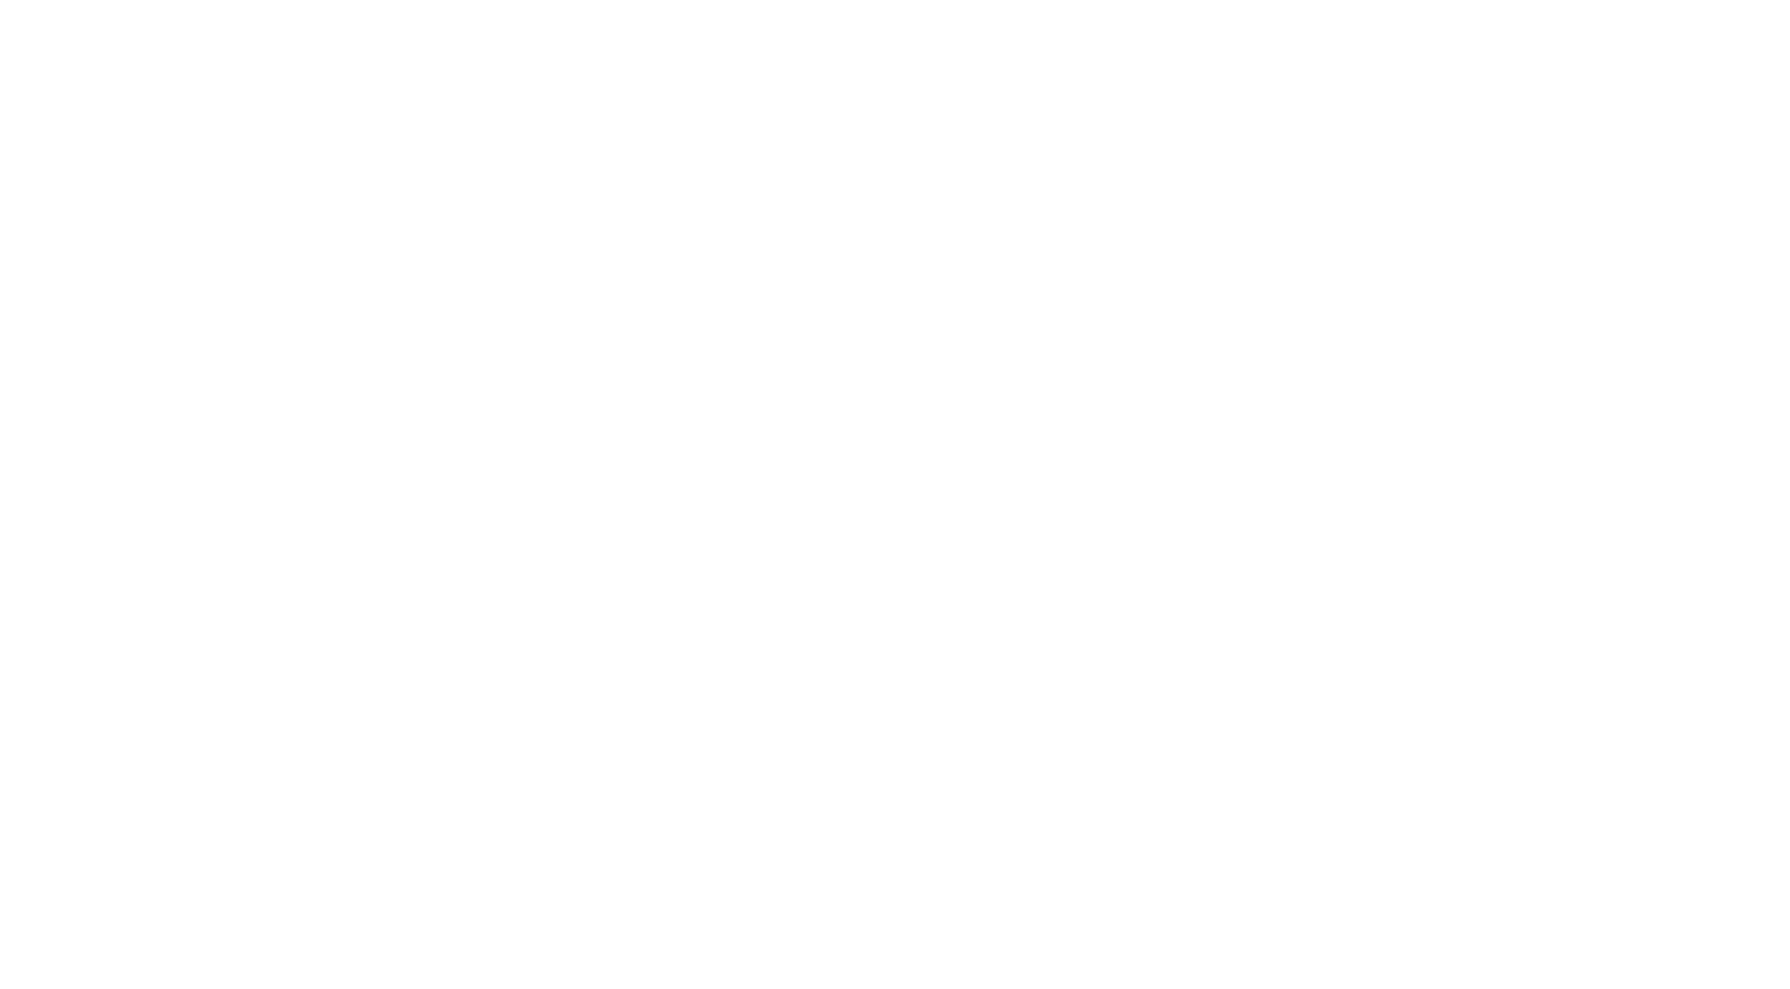

In [9]:
# Cover crop
# show the N2O, Yield, Delta_SOC for cover crops
cur_folder = os.path.join(figure_dir, 'cover_crops_plots', 'Bar_plots')
vars = ['ΔHUMUS_C', 'Δ(HUMUS+RESIDUE)', 'ΔSOC_SUM', 'N2O_emission', 'Yield']
ncols = 3
nrows = int (math.ceil(len(vars) / ncols))
file_names = [f'Bar plots of version effects on {var} for cover crops.png' for var in vars]
show_plots(ncols, nrows, cur_folder, vars, file_names, figsize=(ncols * 6, nrows * 5))

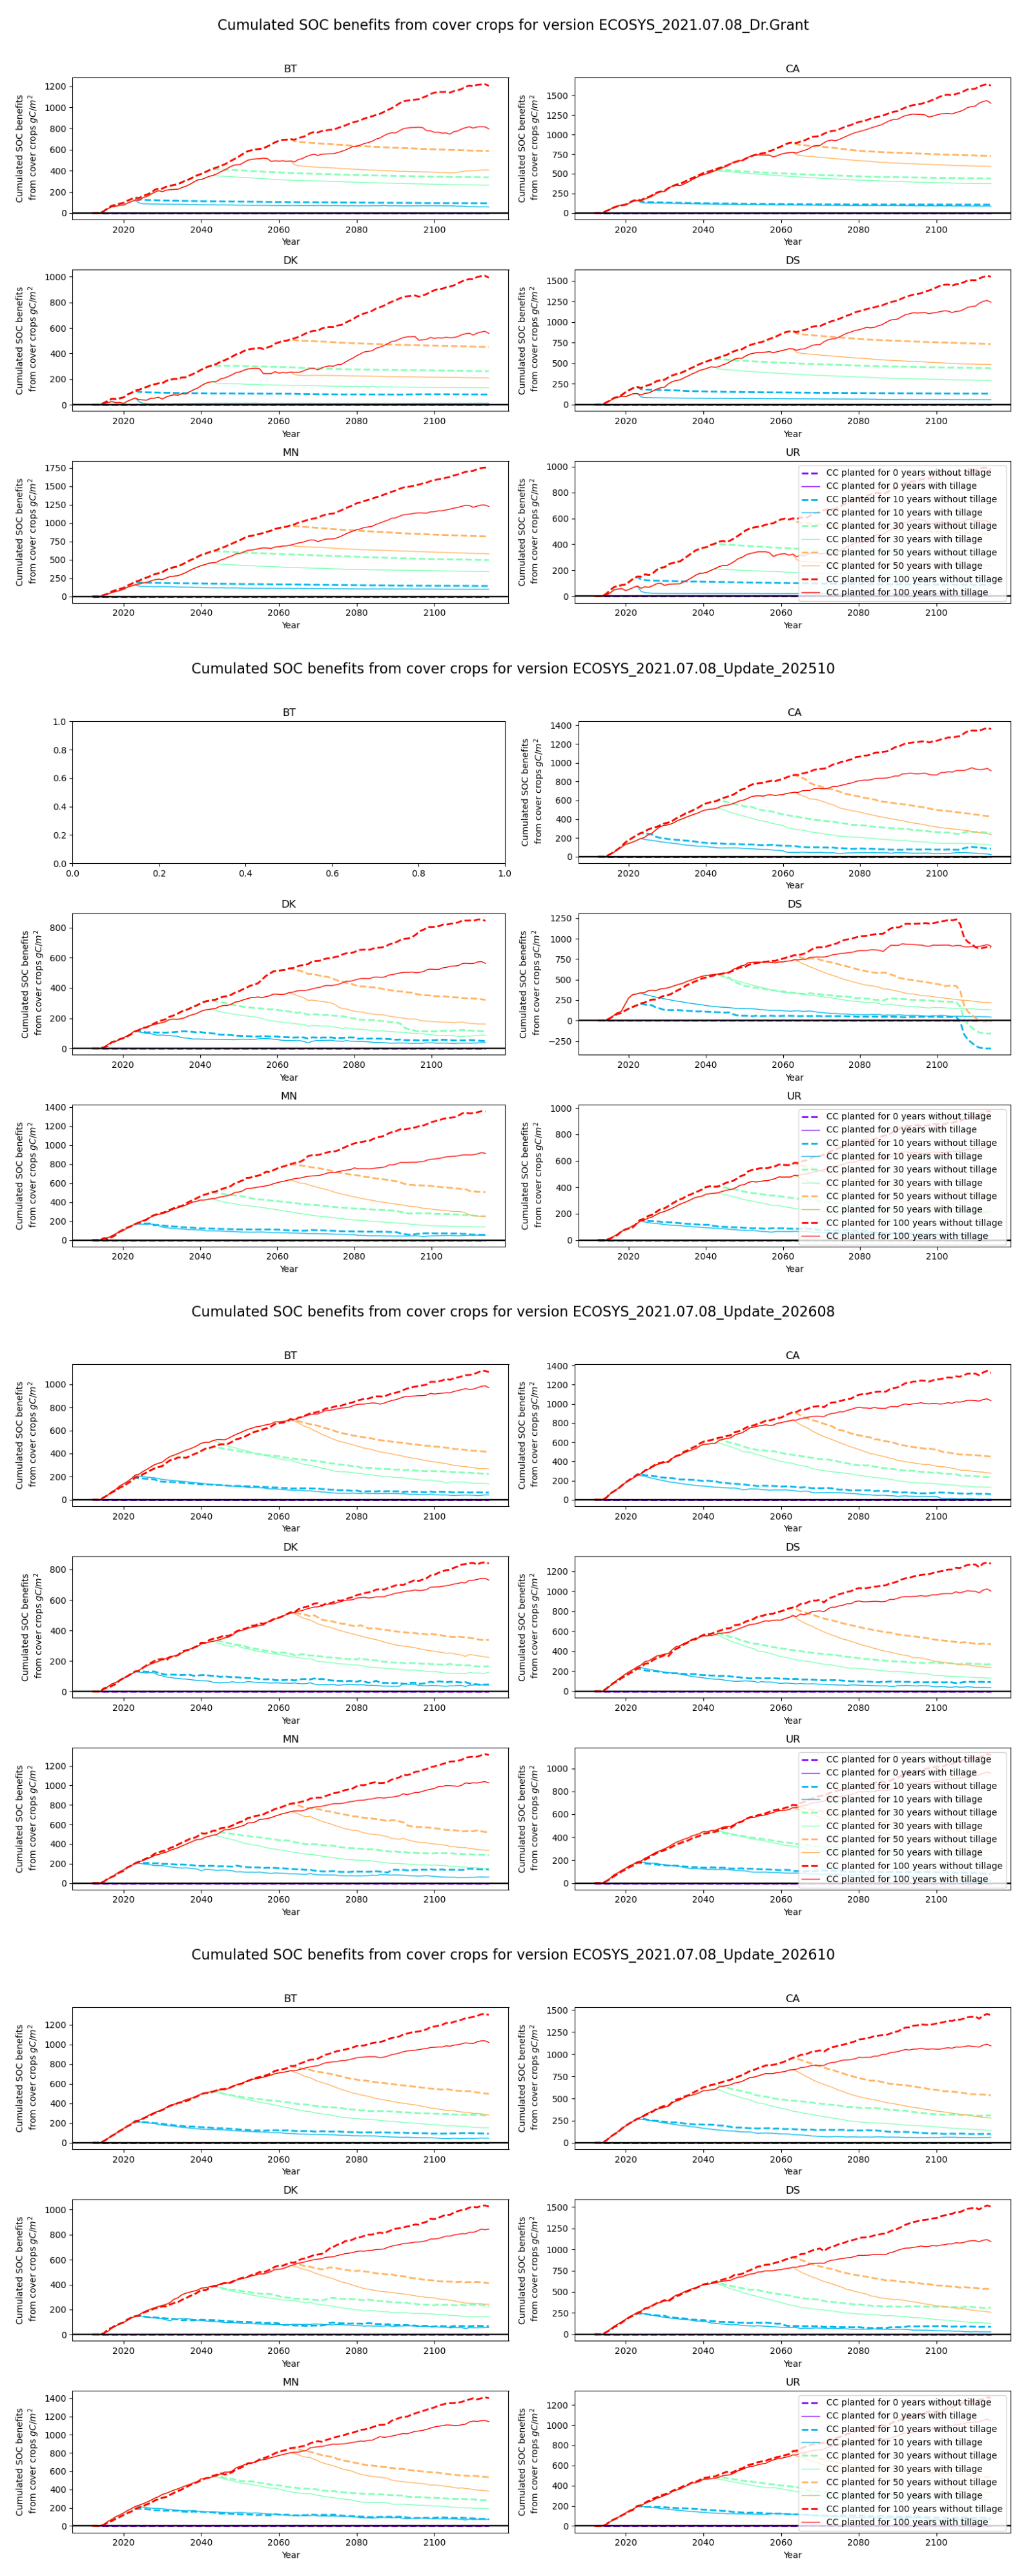

In [10]:
# show the SOC stability for different cover crop years
cur_folder = os.path.join(figure_dir, 'cover_crops_plots')
ncols = 1
nrows = int (math.ceil(len(versions) / ncols))
file_names = [f'SOC benefits from cover crops for {version}.png' for version in versions]
show_plots(ncols, nrows, cur_folder, versions, file_names, figsize=(ncols * 16, nrows * 10))

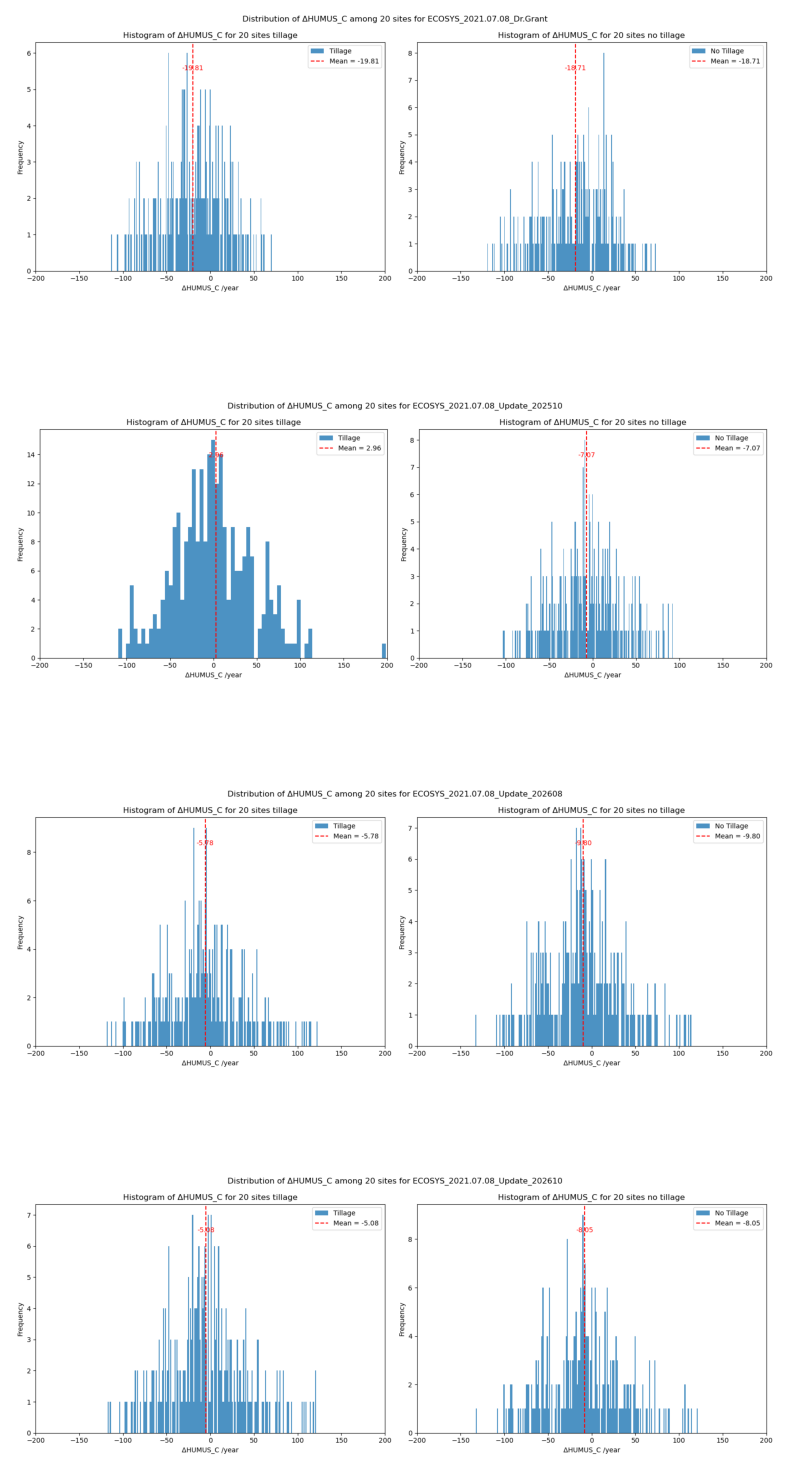

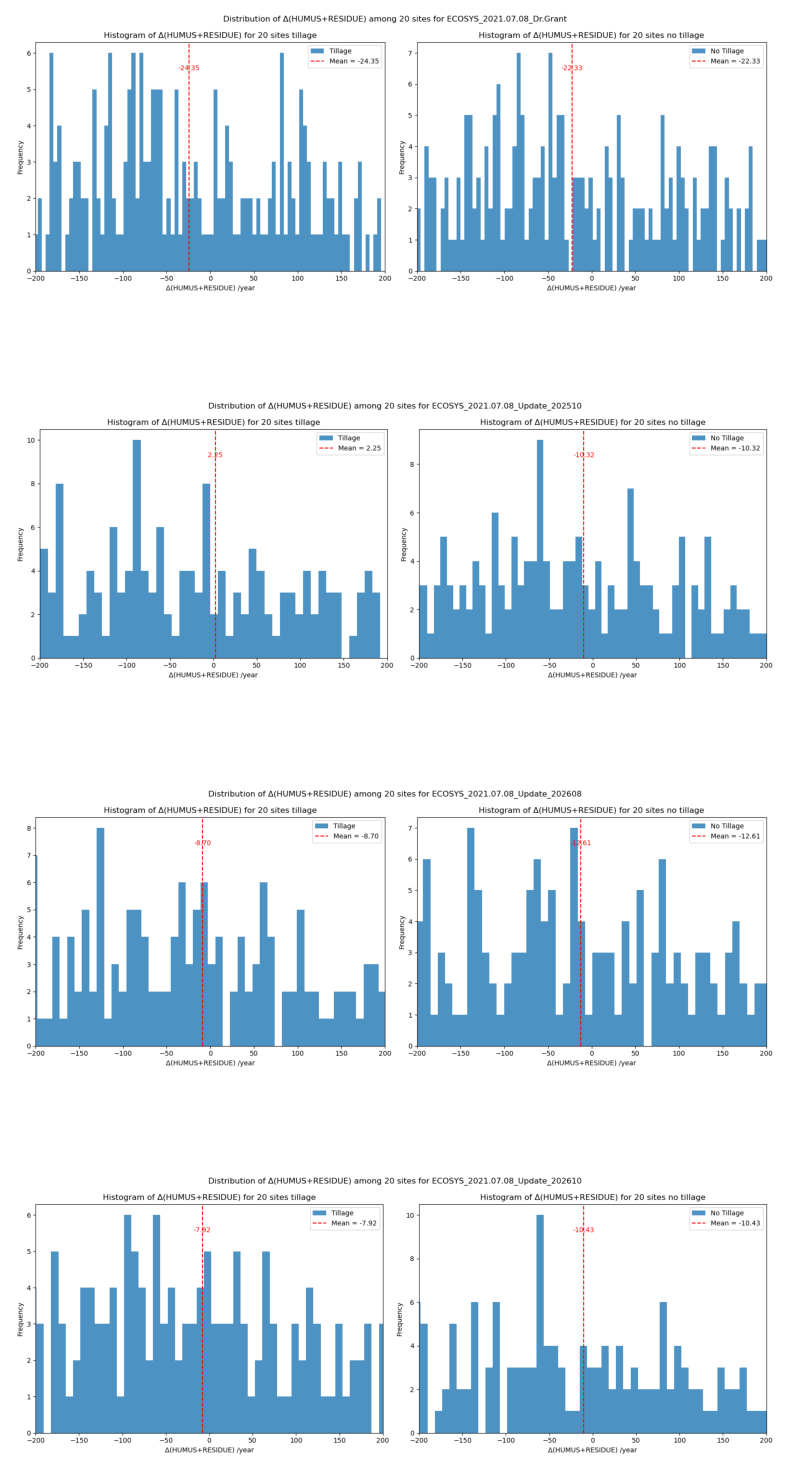

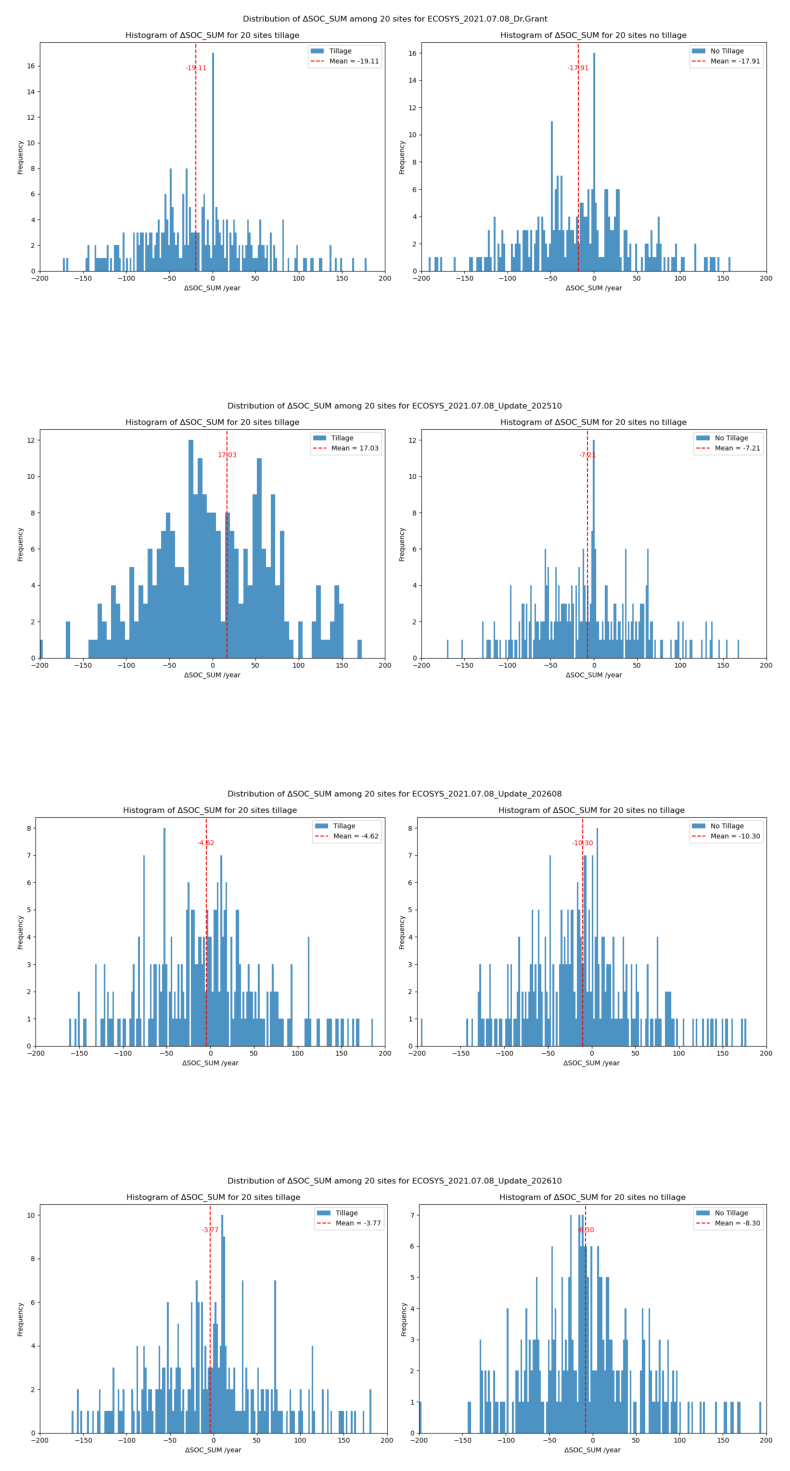

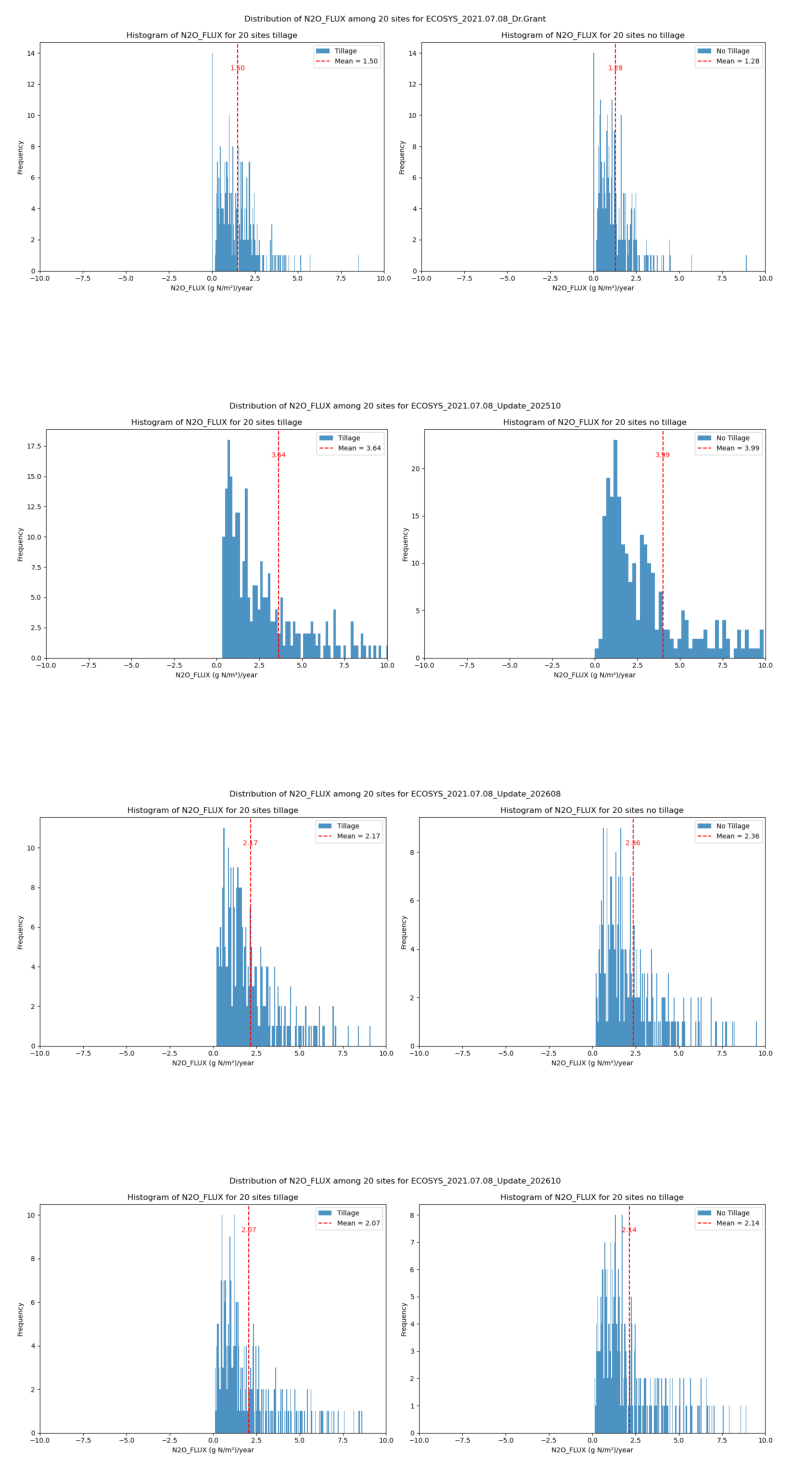

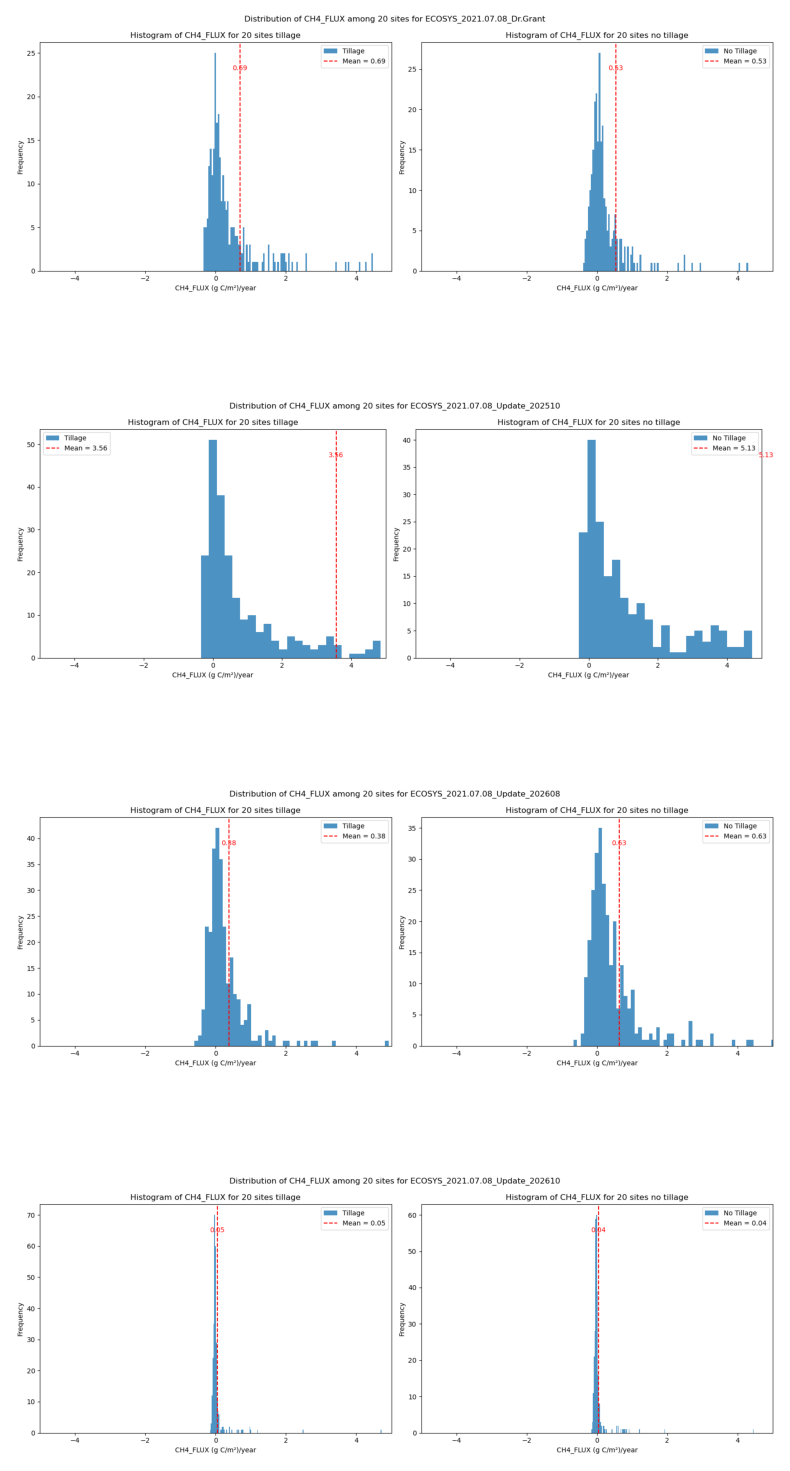

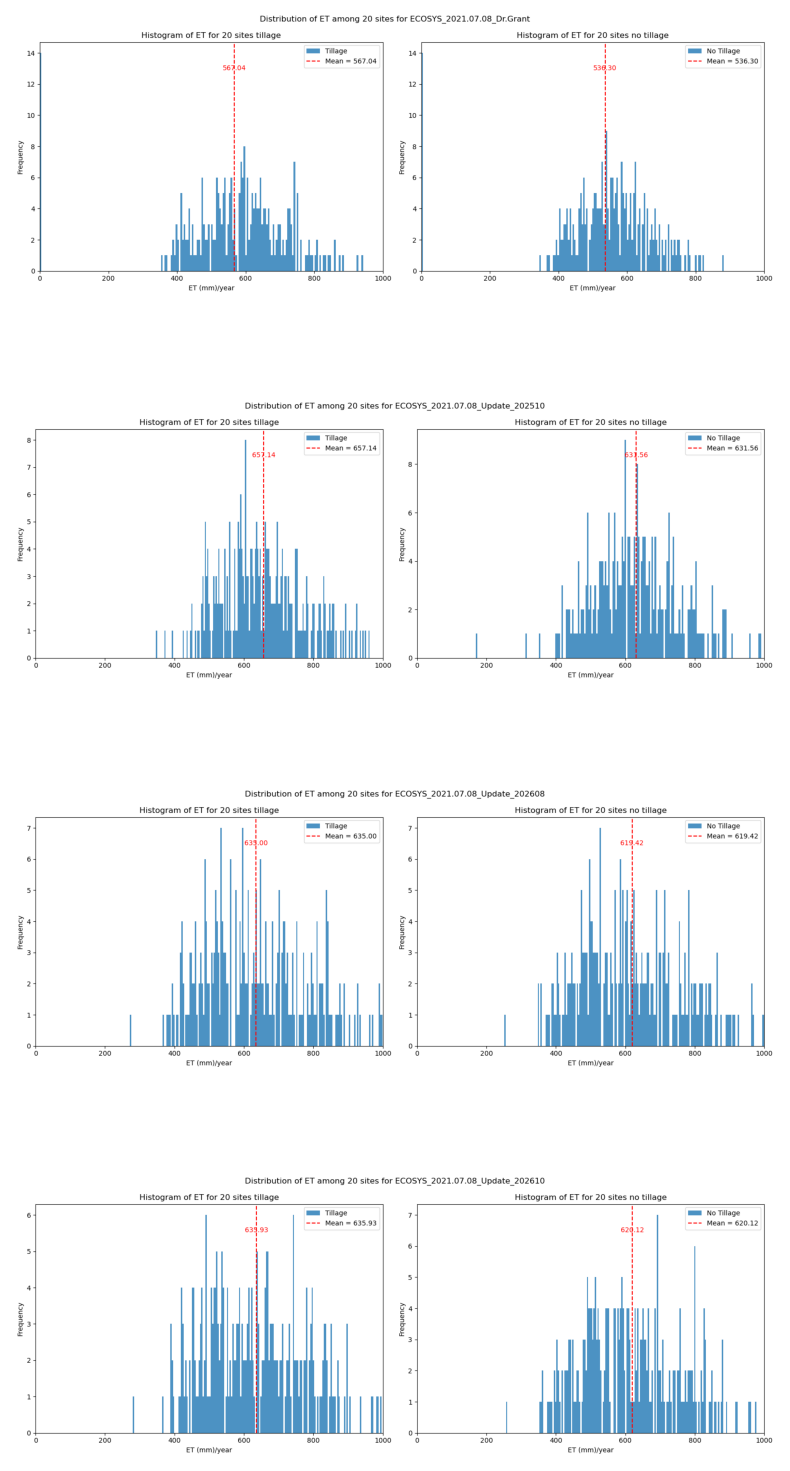

In [11]:
# Histogram of SOC change, N2O emissions, and CH4 emissions, ET for tillage and no-tillage
cur_folder = os.path.join(figure_dir, '20_sites_version_effects_plots', 'Histogram_plots')
vars = ['ΔHUMUS_C', 'Δ(HUMUS+RESIDUE)', 'ΔSOC_SUM', 'N2O_FLUX', 'CH4_FLUX', 'ET']
for var in vars:
    ncols = 1
    nrows = int (math.ceil(len(versions) / ncols))
    file_names = [f'Histogram of {var} for {version}.png' for version in versions]
    show_plots(ncols, nrows, cur_folder, versions, file_names, figsize=(ncols * 8, nrows * 4))